In [1]:
# Cell 1 — Installation
# Run this cell once in a fresh Colab runtime.

!pip -q install neurokit2 xgboost statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 45.4 MB/s eta 0:00:00


In [2]:
# Cell 2 — Imports and reproducibility

import os
import sys
import json
import time
import pickle
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import signal, stats
from scipy.stats import f_oneway, kruskal, shapiro
from statsmodels.stats.multitest import multipletests

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, SelectKBest
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    balanced_accuracy_score, roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier

import neurokit2 as nk

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Setup complete.")

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
NumPy: 2.0.2
Pandas: 2.2.2
Setup complete.


In [3]:
# Cell 3 — Project configuration

PROJECT_NAME = "WESAD 3-Class Stress and Affect Classification"
DATASET_PATH = "/content/drive/MyDrive/WESAD/WESAD"

WINDOW_SECONDS = 30
LABEL_FS = 700
TARGET_LABELS = [1, 2, 3]
LABEL_MAP = {1: "Baseline", 2: "Stress", 3: "Amusement"}

# Window purity prevents transition-heavy windows from being treated as clean examples.
MIN_LABEL_PURITY = 0.80

# Feature-selection settings
TOP_K_FEATURES = 40
PCA_VARIANCE = 0.95

RESULTS_DIR = Path("/content/wesad_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(PROJECT_NAME)
print("Dataset path:", DATASET_PATH)
print("Window:", WINDOW_SECONDS, "seconds")
print("Minimum dominant-label purity:", MIN_LABEL_PURITY)

WESAD 3-Class Stress and Affect Classification
Dataset path: /content/drive/MyDrive/WESAD/WESAD
Window: 30 seconds
Minimum dominant-label purity: 0.8


In [4]:
# Cell 4 — Mount Google Drive

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
# Cell 5 — Verify the WESAD folder

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_PATH}. "
        "Update DATASET_PATH to the extracted WESAD/WESAD folder."
    )

subjects = [
    f"S{i}" for i in range(2, 18)
    if os.path.exists(os.path.join(DATASET_PATH, f"S{i}", f"S{i}.pkl"))
]

print("Subjects found:", subjects)
print("Number of usable subjects:", len(subjects))

if len(subjects) < 5:
    print("WARNING: Fewer than five subjects were found. Check the dataset path.")

Subjects found: ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']
Number of usable subjects: 15


# 1. Dataset and data structure

WESAD contains multimodal wearable physiological signals. The project uses the three target labels:

- **1 — Baseline**
- **2 — Stress**
- **3 — Amusement**

Other labels in the raw label stream are excluded from the three-class experiment.

The chest device contains ECG, EMG, EDA, respiration, temperature and acceleration. The wrist device contains BVP, EDA, temperature and acceleration.

In [6]:
# Cell 6 — Inspect one subject

subject = subjects[0]

with open(os.path.join(DATASET_PATH, subject, f"{subject}.pkl"), "rb") as f:
    sample_data = pickle.load(f, encoding="latin1")

print("Top-level keys:", sample_data.keys())
print("Subject:", sample_data.get("subject"))
print("Chest keys:", sample_data["signal"]["chest"].keys())
print("Wrist keys:", sample_data["signal"]["wrist"].keys())
print("Label shape:", np.asarray(sample_data["label"]).shape)

Top-level keys: dict_keys(['signal', 'label', 'subject'])
Subject: S2
Chest keys: dict_keys(['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp'])
Wrist keys: dict_keys(['ACC', 'BVP', 'EDA', 'TEMP'])
Label shape: (4255300,)


In [7]:
# Cell 7 — Sampling rates and label distribution

SAMPLING_RATES = {
    "chest": {"ACC": 700, "ECG": 700, "EMG": 700, "EDA": 700, "Temp": 700, "Resp": 700},
    "wrist": {"ACC": 32, "BVP": 64, "EDA": 4, "TEMP": 4},
    "label": 700
}

labels = np.asarray(sample_data["label"]).squeeze()

label_counts = pd.Series(labels).value_counts().sort_index()
print("Raw label counts:")
display(label_counts.to_frame("samples"))

print("\nTarget classes:")
for k, v in LABEL_MAP.items():
    print(k, "=", v)

Raw label counts:


,samples
0,2142701
1,800800
2,430500
3,253400
4,537599
6,45500
7,44800



Target classes:
1 = Baseline
2 = Stress
3 = Amusement


# 2. Raw signal visualisation

The next plots document the unstructured nature of the data and provide evidence of data understanding before modelling.

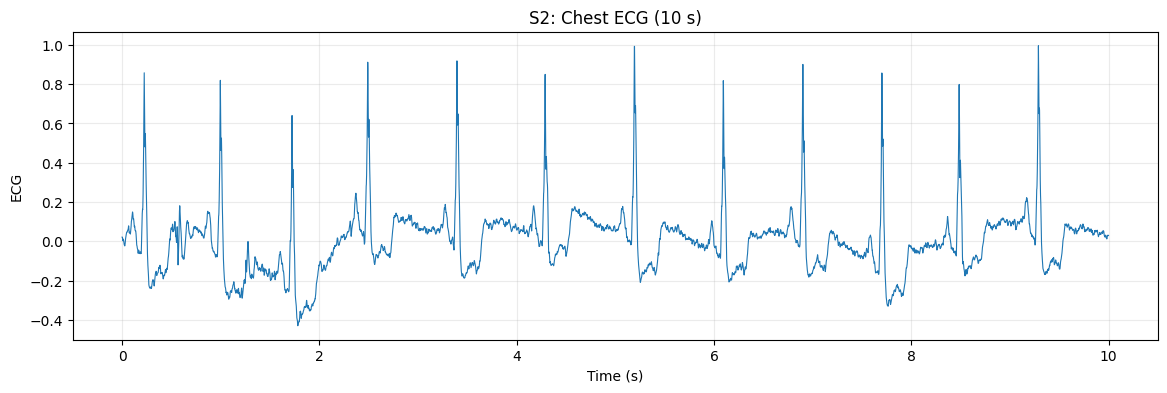

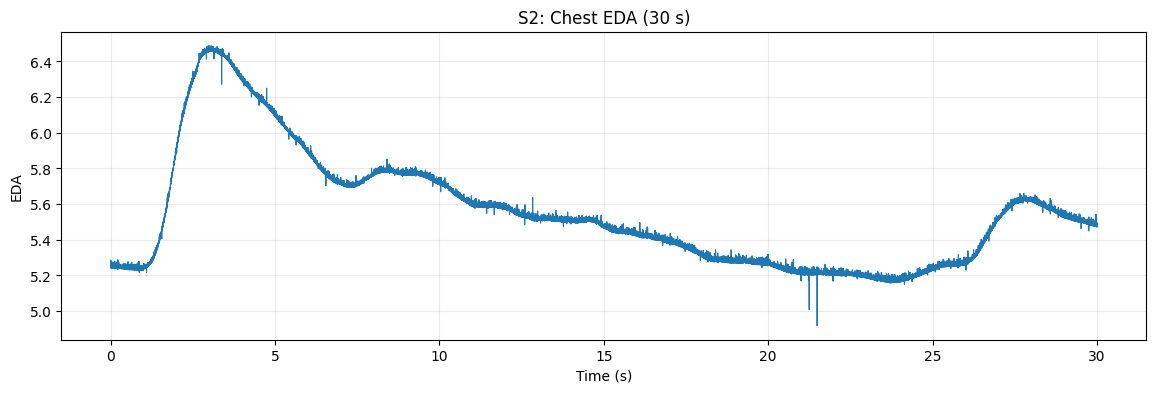

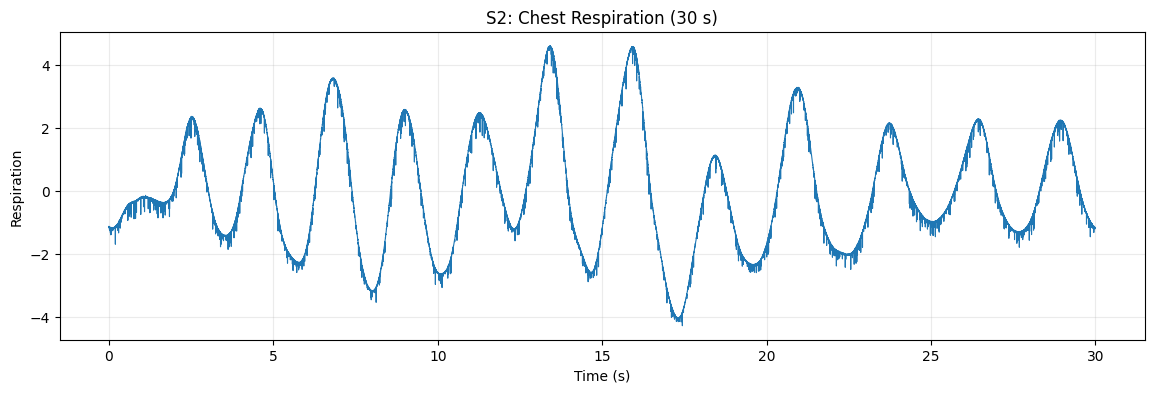

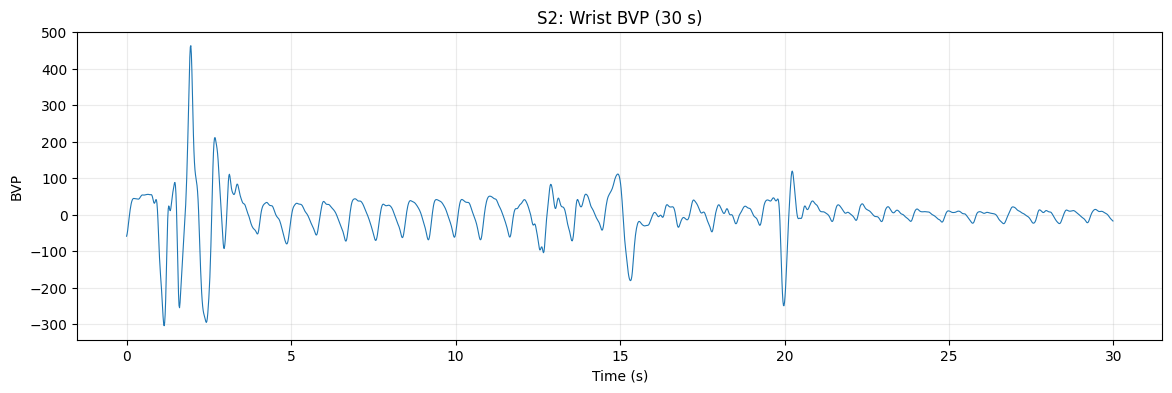

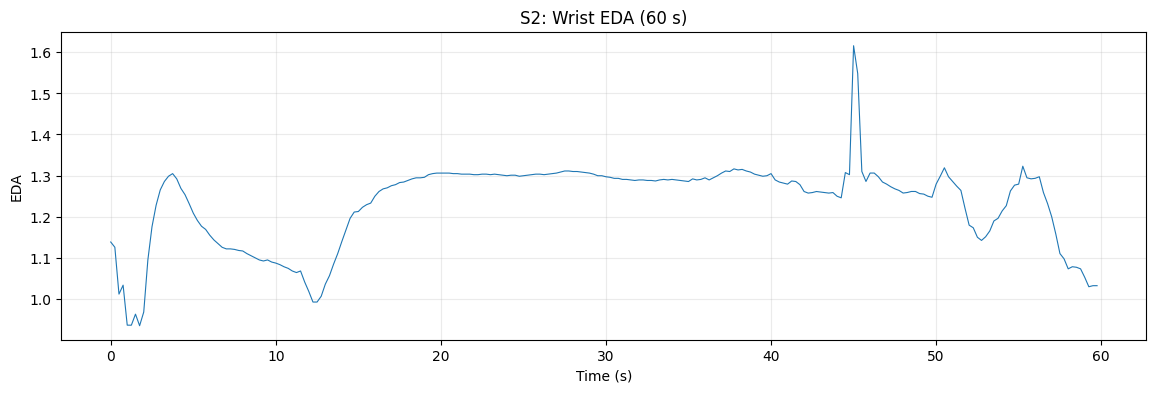

In [8]:
# Cell 8 — Plot raw signals from one subject

def plot_signal(x, fs, seconds, title, ylabel):
    x = np.asarray(x).squeeze()
    n = min(len(x), int(seconds * fs))
    t = np.arange(n) / fs
    plt.figure(figsize=(14, 4))
    plt.plot(t, x[:n], linewidth=0.8)
    plt.xlabel("Time (s)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.show()

chest = sample_data["signal"]["chest"]
wrist = sample_data["signal"]["wrist"]

plot_signal(chest["ECG"], 700, 10, f"{subject}: Chest ECG (10 s)", "ECG")
plot_signal(chest["EDA"], 700, 30, f"{subject}: Chest EDA (30 s)", "EDA")
plot_signal(chest["Resp"], 700, 30, f"{subject}: Chest Respiration (30 s)", "Respiration")
plot_signal(wrist["BVP"], 64, 30, f"{subject}: Wrist BVP (30 s)", "BVP")
plot_signal(wrist["EDA"], 4, 60, f"{subject}: Wrist EDA (60 s)", "EDA")

# 3. Signal preprocessing and time-based synchronisation

The labels are sampled at 700 Hz. The signals themselves have different native sampling rates. Rather than artificially resampling all modalities to 700 Hz, this notebook uses the label timeline to define each 30-second interval and extracts the corresponding number of samples from each signal at its native rate.

This is a key methodological choice: it preserves the native sampling characteristics while ensuring that each feature vector represents the same time interval.

In [9]:

# Cell 9 — General preprocessing utilities with signal smoothing

SMOOTHING_ENABLED = True
SMOOTHING_METHOD = "savgol"


def clean_signal(x):
    x = np.asarray(x).squeeze().astype(float)
    x = np.where(np.isfinite(x), x, np.nan)
    if np.isnan(x).any():
        x = pd.Series(x).interpolate(limit_direction="both").values
    return x


def smooth_signal(x, fs, enabled=SMOOTHING_ENABLED):
    """Light Savitzky-Golay smoothing applied to each window.
    Window length is chosen from the sampling rate and kept odd.
    This is deterministic preprocessing and uses no target information.
    """
    x = clean_signal(x)
    if not enabled or len(x) < 7:
        return x

    # Roughly 0.15–1.25 seconds depending on sampling rate.
    window = max(7, int(round(fs * 0.15)))
    window = min(window, 21)
    if window % 2 == 0:
        window += 1
    if window >= len(x):
        window = len(x) - 1 if len(x) % 2 == 0 else len(x)
    if window < 5:
        return x

    polyorder = min(3, window - 2)
    try:
        return signal.savgol_filter(x, window_length=window, polyorder=polyorder)
    except Exception:
        return x


def bandpass_filter(x, fs, low, high, order=4):
    x = clean_signal(x)
    nyq = fs / 2
    high = min(high, nyq * 0.95)
    low = max(low, 0.001)
    if low >= high or len(x) < max(20, order * 3):
        return x
    sos = signal.butter(order, [low, high], btype="bandpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x)


def lowpass_filter(x, fs, cutoff, order=4):
    x = clean_signal(x)
    nyq = fs / 2
    cutoff = min(cutoff, nyq * 0.95)
    if cutoff <= 0 or len(x) < max(20, order * 3):
        return x
    sos = signal.butter(order, cutoff, btype="lowpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x)


def get_sensor_window(sensor, start_time, end_time, sampling_rate, smooth=False):
    sensor = np.asarray(sensor).squeeze()
    start_idx = int(round(start_time * sampling_rate))
    end_idx = int(round(end_time * sampling_rate))
    start_idx = max(0, start_idx)
    end_idx = min(len(sensor), end_idx)
    window = sensor[start_idx:end_idx]
    return smooth_signal(window, sampling_rate) if smooth else clean_signal(window)


def majority_label(label_window):
    values, counts = np.unique(label_window, return_counts=True)
    idx = np.argmax(counts)
    return int(values[idx]), float(counts[idx] / len(label_window))

print("Smoothing enabled:", SMOOTHING_ENABLED)
print("Smoothing method:", SMOOTHING_METHOD)


Smoothing enabled: True
Smoothing method: savgol


In [10]:
# Cell 10 — Windowing test

WINDOW_LABEL_SAMPLES = WINDOW_SECONDS * LABEL_FS

n_possible = len(labels) // WINDOW_LABEL_SAMPLES
print("Possible non-overlapping 30-second windows:", n_possible)

example = labels[:WINDOW_LABEL_SAMPLES]
dominant, purity = majority_label(example)
print("Example dominant label:", dominant)
print("Example purity:", round(purity, 3))

Possible non-overlapping 30-second windows: 202
Example dominant label: 0
Example purity: 1.0


# 4. Feature extraction

Features are extracted per 30-second window. The feature families include:

- statistical distribution features
- signal energy
- frequency-domain features
- ECG/heart-rate features
- respiration frequency features
- EDA features
- temperature features
- acceleration magnitude features

The feature-extraction stage converts high-frequency signal data into a compact tabular representation suitable for statistical modelling and classical machine learning.

In [11]:
# Cell 11 — Feature functions

def statistical_features(x, prefix):
    x = clean_signal(x)
    if len(x) == 0:
        return {}
    s = pd.Series(x)
    return {
        f"{prefix}_mean": float(np.mean(x)),
        f"{prefix}_std": float(np.std(x)),
        f"{prefix}_median": float(np.median(x)),
        f"{prefix}_min": float(np.min(x)),
        f"{prefix}_max": float(np.max(x)),
        f"{prefix}_range": float(np.ptp(x)),
        f"{prefix}_rms": float(np.sqrt(np.mean(x**2))),
        f"{prefix}_skew": float(s.skew()),
        f"{prefix}_kurtosis": float(s.kurtosis()),
        f"{prefix}_energy": float(np.mean(x**2)),
    }

def frequency_features(x, fs, prefix):
    x = clean_signal(x)
    if len(x) < 8:
        return {}
    freqs, power = signal.periodogram(x, fs=fs)
    if len(power) == 0:
        return {}
    total_power = float(np.sum(power))
    dom = float(freqs[np.argmax(power)]) if total_power > 0 else np.nan
    return {
        f"{prefix}_spectral_power": total_power,
        f"{prefix}_dominant_frequency": dom
    }

def acceleration_magnitude(acc):
    acc = np.asarray(acc)
    if acc.ndim == 1:
        return np.abs(acc)
    return np.sqrt(np.sum(acc.astype(float)**2, axis=1))

def ecg_features(ecg_segment):
    x = clean_signal(ecg_segment)
    # ECG bandpass: approximately 0.5–40 Hz for morphology/peak detection.
    xf = bandpass_filter(x, 700, 0.5, 40)
    out = {}
    out.update(statistical_features(xf, "ECG"))
    out.update(frequency_features(xf, 700, "ECG"))

    try:
        _, rpeaks = nk.ecg_peaks(xf, sampling_rate=700)
        peaks = np.where(rpeaks["ECG_R_Peaks"].values == 1)[0]
        if len(peaks) >= 3:
            rr = np.diff(peaks) / 700.0
            rr = rr[(rr > 0.3) & (rr < 2.0)]
            if len(rr) >= 2:
                hr = 60.0 / rr
                out["ECG_mean_HR"] = float(np.mean(hr))
                out["ECG_std_HR"] = float(np.std(hr))
                out["ECG_mean_RR"] = float(np.mean(rr))
                out["ECG_SDNN"] = float(np.std(rr, ddof=1))
                out["ECG_RMSSD"] = float(np.sqrt(np.mean(np.diff(rr)**2)))
                return out
    except Exception:
        pass

    for k in ["ECG_mean_HR", "ECG_std_HR", "ECG_mean_RR", "ECG_SDNN", "ECG_RMSSD"]:
        out[k] = np.nan
    return out

def eda_features(x, fs, prefix):
    x = clean_signal(x)
    # EDA is low frequency; low-pass at a conservative cutoff.
    xf = lowpass_filter(x, fs, min(1.0, fs * 0.45))
    out = {}
    out.update(statistical_features(xf, prefix))
    out.update(frequency_features(xf, fs, prefix))
    # Simple slope/variation proxy for phasic activity.
    if len(xf) > 1:
        diff = np.diff(xf)
        out[f"{prefix}_mean_abs_change"] = float(np.mean(np.abs(diff)))
        out[f"{prefix}_positive_slope_fraction"] = float(np.mean(diff > 0))
    return out

def respiration_features(x):
    x = clean_signal(x)
    xf = bandpass_filter(x, 700, 0.05, 1.0)
    out = {}
    out.update(statistical_features(xf, "RESP"))
    out.update(frequency_features(xf, 700, "RESP"))
    try:
        peaks, _ = signal.find_peaks(xf, distance=int(700/1.2))
        if len(peaks) >= 2:
            intervals = np.diff(peaks) / 700.0
            rate = 60.0 / intervals
            rate = rate[(rate > 3) & (rate < 40)]
            out["RESP_mean_rate_bpm"] = float(np.mean(rate)) if len(rate) else np.nan
            out["RESP_std_rate_bpm"] = float(np.std(rate)) if len(rate) else np.nan
        else:
            out["RESP_mean_rate_bpm"] = np.nan
            out["RESP_std_rate_bpm"] = np.nan
    except Exception:
        out["RESP_mean_rate_bpm"] = np.nan
        out["RESP_std_rate_bpm"] = np.nan
    return out

In [12]:

# Cell 12 — Extract one 30-second window with smoothing

def extract_window_features(data, start_time, end_time):
    chest = data["signal"]["chest"]
    wrist = data["signal"]["wrist"]
    features = {}

    # ECG is handled by its dedicated band-pass/R-peak pipeline; do not smooth it here.
    features.update(ecg_features(
        get_sensor_window(chest["ECG"], start_time, end_time, 700, smooth=False)
    ))

    # Light smoothing is applied to slower/noisier modalities before feature extraction.
    features.update(eda_features(
        get_sensor_window(chest["EDA"], start_time, end_time, 700, smooth=SMOOTHING_ENABLED),
        700, "Chest_EDA"
    ))
    features.update(respiration_features(
        get_sensor_window(chest["Resp"], start_time, end_time, 700, smooth=SMOOTHING_ENABLED)
    ))
    features.update(statistical_features(
        get_sensor_window(chest["Temp"], start_time, end_time, 700, smooth=SMOOTHING_ENABLED),
        "Chest_TEMP"
    ))
    features.update(statistical_features(
        get_sensor_window(wrist["BVP"], start_time, end_time, 64, smooth=SMOOTHING_ENABLED),
        "Wrist_BVP"
    ))
    features.update(eda_features(
        get_sensor_window(wrist["EDA"], start_time, end_time, 4, smooth=SMOOTHING_ENABLED),
        4, "Wrist_EDA"
    ))
    features.update(statistical_features(
        get_sensor_window(wrist["TEMP"], start_time, end_time, 4, smooth=SMOOTHING_ENABLED),
        "Wrist_TEMP"
    ))
    features.update(statistical_features(
        acceleration_magnitude(
            get_sensor_window(wrist["ACC"], start_time, end_time, 32, smooth=SMOOTHING_ENABLED)
        ),
        "Wrist_ACC"
    ))
    return features

test_features = extract_window_features(sample_data, 0, 30)
print("Extracted features:", len(test_features))
display(pd.DataFrame([test_features]).T.head(30))


Extracted features: 99


,0
ECG_mean,0.000022
ECG_std,0.145522
ECG_median,0.013070
ECG_min,-0.277352
ECG_max,0.806584
ECG_range,1.083936
ECG_rms,0.145522
ECG_skew,1.853093
ECG_kurtosis,7.009791
ECG_energy,0.021177


In [13]:
# Cell 13 — Build one subject's complete feature table

def extract_subject_features(subject, dataset_path, window_seconds=30, min_purity=0.80):
    path = os.path.join(dataset_path, subject, f"{subject}.pkl")
    with open(path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    labels = np.asarray(data["label"]).squeeze()
    win_n = int(window_seconds * LABEL_FS)
    n_windows = len(labels) // win_n
    rows = []

    for w in range(n_windows):
        a = w * win_n
        b = a + win_n
        dominant, purity = majority_label(labels[a:b])

        if dominant not in TARGET_LABELS or purity < min_purity:
            continue

        start_time = a / LABEL_FS
        end_time = b / LABEL_FS

        try:
            feats = extract_window_features(data, start_time, end_time)
        except Exception as exc:
            print(f"Warning: {subject} window {w} failed: {exc}")
            continue

        feats["subject"] = subject
        feats["window_id"] = w
        feats["label"] = dominant
        feats["label_name"] = LABEL_MAP[dominant]
        feats["label_purity"] = purity
        rows.append(feats)

    return pd.DataFrame(rows)

# Test on one subject first
s2_features = extract_subject_features(subject, DATASET_PATH, WINDOW_SECONDS, MIN_LABEL_PURITY)
print("S2 feature table:", s2_features.shape)
display(s2_features.head())

S2 feature table: (69, 104)


,ECG_mean,ECG_std,ECG_median,ECG_min,ECG_max,ECG_range,ECG_rms,ECG_skew,ECG_kurtosis,ECG_energy,...,Wrist_ACC_range,Wrist_ACC_rms,Wrist_ACC_skew,Wrist_ACC_kurtosis,Wrist_ACC_energy,subject,window_id,label,label_name,label_purity
0,0.000162,0.141644,0.020673,-0.363680,0.765225,1.128905,0.141644,1.025964,3.598945,0.020063,...,98.668901,64.487063,1.900127,14.286186,4158.581250,S2,11,1,Baseline,1.0
1,-0.000709,0.152769,0.032398,-0.299703,0.774068,1.073770,0.152770,0.985403,3.696825,0.023339,...,48.428677,63.228554,-1.244435,25.431036,3997.850000,S2,12,1,Baseline,1.0
2,0.000491,0.152845,0.030071,-0.292652,0.799544,1.092195,0.152845,0.989512,4.097187,0.023362,...,21.278496,63.445843,0.474337,13.186475,4025.375000,S2,13,1,Baseline,1.0
3,0.000507,0.206015,0.033866,-1.495874,1.449755,2.945629,0.206016,-0.539946,16.326461,0.042442,...,13.953537,63.496883,0.151060,8.970734,4031.854167,S2,14,1,Baseline,1.0
4,-0.000076,0.150589,0.033682,-0.300044,0.744503,1.044547,0.150589,0.893982,3.040355,0.022677,...,71.120710,63.959216,1.625804,12.293087,4090.781250,S2,15,1,Baseline,1.0


In [14]:
# Cell 14 — Extract all subjects

all_subject_tables = []
start = time.time()

for s in subjects:
    print("Processing", s)
    df_s = extract_subject_features(
        s, DATASET_PATH, WINDOW_SECONDS, MIN_LABEL_PURITY
    )
    print("  windows:", len(df_s))
    all_subject_tables.append(df_s)

features_df = pd.concat(all_subject_tables, ignore_index=True)

print("\nFinal feature table:", features_df.shape)
print("Elapsed minutes:", round((time.time() - start) / 60, 2))

Processing S2
  windows: 69
Processing S3
  windows: 70
Processing S4
  windows: 70
Processing S5
  windows: 72
Processing S6
  windows: 71
Processing S7
  windows: 71
Processing S8
  windows: 71
Processing S9
  windows: 71
Processing S10
  windows: 74
Processing S11
  windows: 73
Processing S13
  windows: 73
Processing S14
  windows: 73
Processing S15
  windows: 73
Processing S16
  windows: 71
Processing S17
  windows: 75

Final feature table: (1077, 104)
Elapsed minutes: 4.4


In [15]:
# Cell 15 — Basic quality checks

print("Rows:", len(features_df))
print("Subjects:", features_df["subject"].nunique())
print("Features:", len([c for c in features_df.columns if c not in ["subject","window_id","label","label_name","label_purity"]]))

print("\nClass distribution:")
display(features_df["label_name"].value_counts())

print("\nMissing-value summary (top 20):")
display(features_df.isna().sum().sort_values(ascending=False).head(20))

Rows: 1077
Subjects: 15
Features: 99

Class distribution:


,count
label_name,
Baseline,577
Stress,322
Amusement,178



Missing-value summary (top 20):


,0
ECG_mean_HR,1077
ECG_std_HR,1077
ECG_mean_RR,1077
ECG_RMSSD,1077
ECG_SDNN,1077
ECG_mean,0
ECG_median,0
ECG_std,0
ECG_skew,0
ECG_rms,0


In [16]:
# Cell 16 — Save intermediate feature dataset

feature_csv = RESULTS_DIR / "wesad_30s_features.csv"
features_df.to_csv(feature_csv, index=False)
print("Saved:", feature_csv)

Saved: /content/wesad_results/wesad_30s_features.csv


# 5. Exploratory Data Analysis

EDA should answer questions about class balance, distributions, outliers and relationships between physiological features before classification.

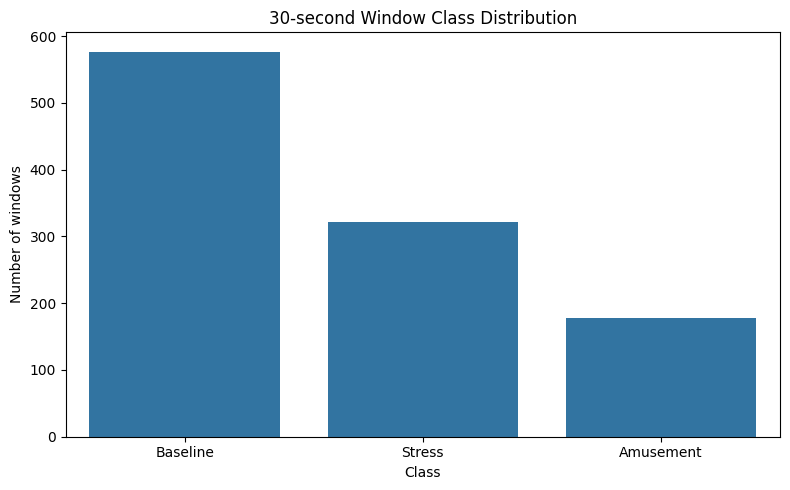

In [17]:
# Cell 17 — Class distribution

plt.figure(figsize=(8,5))
sns.countplot(data=features_df, x="label_name", order=["Baseline","Stress","Amusement"])
plt.title("30-second Window Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of windows")
plt.tight_layout()
plt.show()

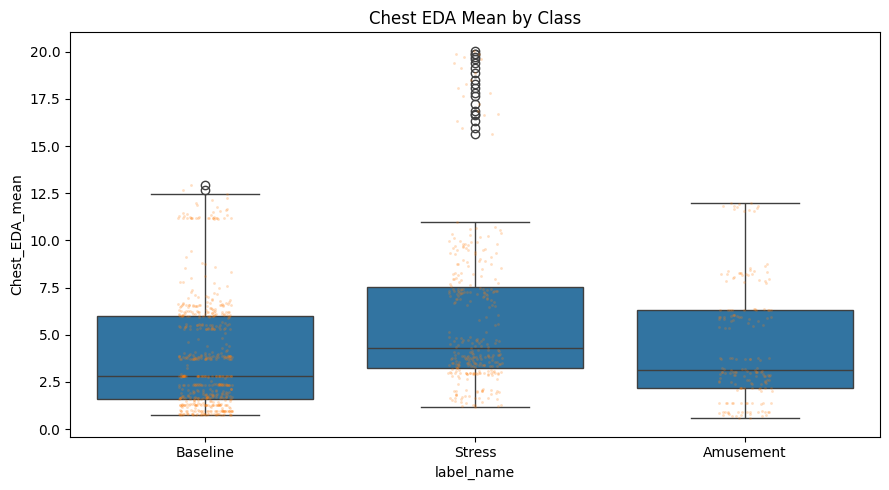

In [18]:
# Cell 18 — Feature distributions

candidate = "Chest_EDA_mean"
if candidate in features_df.columns:
    plt.figure(figsize=(9,5))
    sns.boxplot(data=features_df, x="label_name", y=candidate,
                order=["Baseline","Stress","Amusement"])
    sns.stripplot(data=features_df, x="label_name", y=candidate,
                  order=["Baseline","Stress","Amusement"], alpha=0.25, size=2)
    plt.title("Chest EDA Mean by Class")
    plt.tight_layout()
    plt.show()
else:
    print("Feature not available:", candidate)

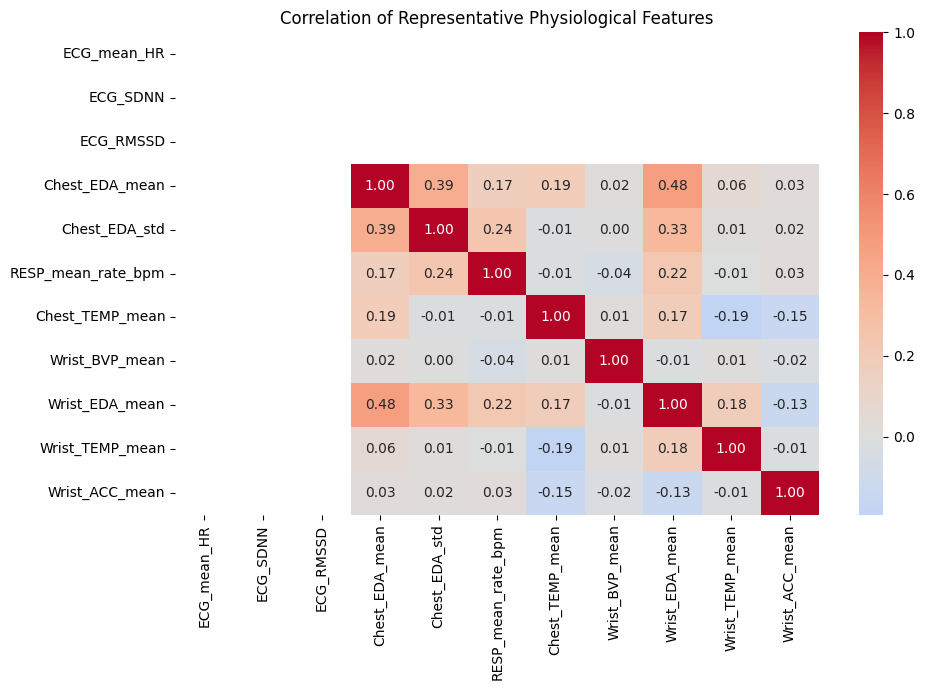

In [19]:
# Cell 19 — Correlation heatmap for selected feature subset

preferred = [
    "ECG_mean_HR", "ECG_SDNN", "ECG_RMSSD",
    "Chest_EDA_mean", "Chest_EDA_std",
    "RESP_mean_rate_bpm", "Chest_TEMP_mean",
    "Wrist_BVP_mean", "Wrist_EDA_mean", "Wrist_TEMP_mean",
    "Wrist_ACC_mean"
]
available = [c for c in preferred if c in features_df.columns]

plt.figure(figsize=(10,7))
sns.heatmap(features_df[available].corr(), annot=True, fmt=".2f", center=0, cmap="coolwarm")
plt.title("Correlation of Representative Physiological Features")
plt.tight_layout()
plt.show()

# 6. Statistical modelling and inference

For each numeric feature, the notebook compares the three classes.

- One-way ANOVA is reported when used as a parametric omnibus test.
- Kruskal-Wallis is also reported as a non-parametric robustness check.
- Eta-squared is used as an effect-size measure for ANOVA.
- Benjamini-Hochberg FDR correction is applied across the feature-wise p-values.

These tests are **descriptive/inferential evidence**, not a substitute for the leakage-safe predictive evaluation.

In [20]:
# Cell 20 — Statistical tests across all features

META_COLS = ["subject", "window_id", "label", "label_name", "label_purity"]
feature_columns = [c for c in features_df.columns if c not in META_COLS]

stat_rows = []

for col in feature_columns:
    x = features_df[col].replace([np.inf, -np.inf], np.nan)
    groups_vals = [
        x[features_df["label"] == lab].dropna().values
        for lab in TARGET_LABELS
    ]
    if any(len(g) < 3 for g in groups_vals):
        continue

    try:
        f_stat, p_anova = f_oneway(*groups_vals)
    except Exception:
        f_stat, p_anova = np.nan, np.nan

    try:
        h_stat, p_kw = kruskal(*groups_vals)
    except Exception:
        h_stat, p_kw = np.nan, np.nan

    grand = np.concatenate(groups_vals)
    grand_mean = np.mean(grand)
    ss_between = sum(len(g) * (np.mean(g) - grand_mean)**2 for g in groups_vals)
    ss_total = np.sum((grand - grand_mean)**2)
    eta2 = ss_between / ss_total if ss_total > 0 else np.nan

    stat_rows.append({
        "feature": col,
        "anova_F": f_stat,
        "anova_p": p_anova,
        "kruskal_H": h_stat,
        "kruskal_p": p_kw,
        "eta_squared": eta2
    })

stats_df = pd.DataFrame(stat_rows)

valid = stats_df["anova_p"].notna()
stats_df.loc[valid, "anova_p_fdr"] = multipletests(
    stats_df.loc[valid, "anova_p"], method="fdr_bh"
)[1]

stats_df = stats_df.sort_values("anova_p_fdr")
display(stats_df.head(20))

,feature,anova_F,anova_p,kruskal_H,kruskal_p,eta_squared,anova_p_fdr
38,RESP_mean_rate_bpm,218.473287,2.469038e-80,310.534383,3.700970e-68,0.289187,2.320896e-78
39,RESP_std_rate_bpm,183.475056,2.849807e-69,259.701134,4.042177e-57,0.254658,1.339409e-67
30,RESP_max,169.920848,7.657331e-65,295.195301,7.927839e-65,0.240368,2.399297e-63
27,RESP_std,164.389282,5.201653e-63,263.384515,6.408838e-58,0.234377,9.779108e-62
32,RESP_rms,164.631768,4.320431e-63,263.558125,5.875981e-58,0.234641,9.779108e-62
24,Chest_EDA_mean_abs_change,160.006741,1.506379e-61,300.003822,7.161399e-66,0.229563,2.359993e-60
31,RESP_range,141.184686,3.650287e-55,265.541262,2.179955e-58,0.208180,4.901813e-54
72,Wrist_EDA_mean_abs_change,140.583994,5.874707e-55,349.380563,1.358234e-76,0.207478,6.902780e-54
35,RESP_energy,127.527120,2.027059e-50,263.558125,5.875981e-58,0.191907,2.117151e-49
36,RESP_spectral_power,127.314108,2.407880e-50,263.384515,6.408838e-58,0.191647,2.263407e-49


In [21]:
# Cell 21 — Report statistically significant features

sig_stats = stats_df[
    stats_df["anova_p_fdr"] < 0.05
].copy()

print("FDR-significant features:", len(sig_stats))
display(sig_stats.head(30))

FDR-significant features: 77


,feature,anova_F,anova_p,kruskal_H,kruskal_p,eta_squared,anova_p_fdr
38,RESP_mean_rate_bpm,218.473287,2.469038e-80,310.534383,3.700970e-68,0.289187,2.320896e-78
39,RESP_std_rate_bpm,183.475056,2.849807e-69,259.701134,4.042177e-57,0.254658,1.339409e-67
30,RESP_max,169.920848,7.657331e-65,295.195301,7.927839e-65,0.240368,2.399297e-63
27,RESP_std,164.389282,5.201653e-63,263.384515,6.408838e-58,0.234377,9.779108e-62
32,RESP_rms,164.631768,4.320431e-63,263.558125,5.875981e-58,0.234641,9.779108e-62
24,Chest_EDA_mean_abs_change,160.006741,1.506379e-61,300.003822,7.161399e-66,0.229563,2.359993e-60
31,RESP_range,141.184686,3.650287e-55,265.541262,2.179955e-58,0.208180,4.901813e-54
72,Wrist_EDA_mean_abs_change,140.583994,5.874707e-55,349.380563,1.358234e-76,0.207478,6.902780e-54
35,RESP_energy,127.527120,2.027059e-50,263.558125,5.875981e-58,0.191907,2.117151e-49
36,RESP_spectral_power,127.314108,2.407880e-50,263.384515,6.408838e-58,0.191647,2.263407e-49


# 7. Leakage-safe predictive dataset

The most important methodological rule in this notebook is that preprocessing learned from data — imputation, scaling, feature selection and PCA — must be fitted only on the training subjects inside each LOSO fold.

This prevents information from the held-out subject leaking into model development.

In [22]:
# Cell 22 — Prepare X, y and groups

X_all = features_df[feature_columns].copy()
y_all = features_df["label"].astype(int).copy()
groups_all = features_df["subject"].copy()

X_all = X_all.replace([np.inf, -np.inf], np.nan)

print("X shape:", X_all.shape)
print("y shape:", y_all.shape)
print("Subjects:", groups_all.nunique())

X shape: (1077, 99)
y shape: (1077,)
Subjects: 15


In [24]:
# Remove completely empty columns explicitly

valid_mi_columns = X_all.columns[
    ~X_all.isna().all()
].tolist()

X_mi = X_all[valid_mi_columns]

X_mi = SimpleImputer(
    strategy="median"
).fit_transform(X_mi)

mi = mutual_info_classif(
    X_mi,
    y_all,
    random_state=SEED
)

mi_df = pd.DataFrame({
    "feature": valid_mi_columns,
    "mutual_information": mi
}).sort_values(
    "mutual_information",
    ascending=False
).reset_index(drop=True)

display(mi_df.head(25))

,feature,mutual_information
0,Chest_EDA_rms,0.476211
1,Chest_EDA_energy,0.475491
2,Chest_EDA_mean,0.473903
3,Chest_EDA_median,0.469995
4,Chest_EDA_min,0.469352
5,Chest_EDA_max,0.466224
6,Wrist_EDA_min,0.350533
7,Wrist_EDA_median,0.341001
8,Wrist_EDA_rms,0.333285
9,Wrist_EDA_energy,0.332748


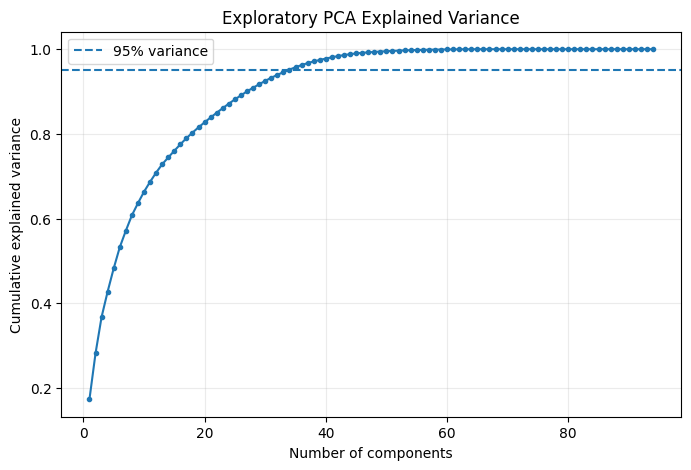

Components needed for 0.95 variance: 34


In [25]:
# Cell 24 — PCA exploration

X_scaled_exploratory = StandardScaler().fit_transform(
    SimpleImputer(strategy="median").fit_transform(X_all)
)
pca_exploratory = PCA().fit(X_scaled_exploratory)
cumvar = np.cumsum(pca_exploratory.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cumvar)+1), cumvar, marker="o", markersize=3)
plt.axhline(PCA_VARIANCE, linestyle="--", label=f"{PCA_VARIANCE:.0%} variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Exploratory PCA Explained Variance")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

n_pca = int(np.argmax(cumvar >= PCA_VARIANCE) + 1)
print("Components needed for", PCA_VARIANCE, "variance:", n_pca)

# 7b. Leakage-safe feature selection experiment

The assignment explicitly includes feature selection/extraction methods. Feature extraction is already performed above; this additional experiment evaluates **Mutual Information SelectKBest** inside each LOSO training fold.

The selector is therefore never fitted on the held-out subject.


# 8. Enhanced machine-learning experiment

This section uses **micro-averaged** precision, recall and F1 as the primary classification scores, as requested. For a single-label multiclass problem, micro-F1 is numerically equivalent to accuracy because all predictions contribute equally to the global counts. **Balanced accuracy is retained as a secondary diagnostic** so that class imbalance is not hidden.

The experiment uses **Leave-One-Subject-Out (LOSO)** validation. Preprocessing is fitted inside every training fold, preventing information leakage between subjects.


In [26]:

# Cell 25 — Micro-averaged leakage-safe LOSO evaluation

CLASS_ORDER = [1, 2, 3]


def make_preprocess_pipeline(model, use_pca=False, pca_variance=0.95):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
    if use_pca:
        steps.append((
            "pca",
            PCA(
                n_components=pca_variance,
                svd_solver="full",
                random_state=SEED
            )
        ))
    steps.append(("model", clone(model)))
    return Pipeline(steps)


def calculate_micro_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_micro": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "recall_micro": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "f1_micro": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred)
    }


def evaluate_single_loso_micro(model_name, model, X, y, groups, use_pca=False):
    logo = LeaveOneGroupOut()
    rows = []
    fold_predictions = []

    print("=" * 85)
    print(f"Running: {model_name}")
    print("=" * 85)

    for fold, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        test_subject = groups.iloc[test_idx].iloc[0]

        pipe = make_preprocess_pipeline(
            model,
            use_pca=use_pca,
            pca_variance=PCA_VARIANCE
        )

        y_train_fit = y_train - 1 if model_name == "XGBoost" else y_train
        pipe.fit(X_train, y_train_fit)
        pred = pipe.predict(X_test)

        if model_name == "XGBoost":
            pred = pred.astype(int) + 1

        metrics = calculate_micro_metrics(y_test, pred)
        roc_auc = np.nan

        if hasattr(pipe, "predict_proba"):
            try:
                proba = pipe.predict_proba(X_test)
                y_bin = label_binarize(y_test, classes=CLASS_ORDER)
                roc_auc = roc_auc_score(
                    y_bin,
                    proba,
                    multi_class="ovr",
                    average="micro"
                )
            except Exception:
                pass

        rows.append({
            "model": model_name,
            "fold": fold,
            "test_subject": test_subject,
            **metrics,
            "roc_auc_micro": roc_auc
        })

        for i, p in zip(test_idx, pred):
            fold_predictions.append({
                "subject": groups.iloc[i],
                "true": int(y.iloc[i]),
                "pred": int(p)
            })

        print(
            f"Fold {fold:02d} | Subject {test_subject} | "
            f"Micro-F1={metrics['f1_micro']:.4f} | "
            f"Balanced Acc={metrics['balanced_accuracy']:.4f}"
        )

    results_df = pd.DataFrame(rows)
    predictions_df = pd.DataFrame(fold_predictions)

    metric_map = {
        "Accuracy": "accuracy",
        "Precision Micro": "precision_micro",
        "Recall Micro": "recall_micro",
        "F1 Micro": "f1_micro",
        "Balanced Accuracy": "balanced_accuracy",
        "ROC-AUC Micro": "roc_auc_micro"
    }

    summary_df = pd.DataFrame({
        "Metric": list(metric_map.keys()),
        "Mean": [results_df[c].mean() for c in metric_map.values()],
        "Std": [results_df[c].std() for c in metric_map.values()]
    })

    print("\n" + "=" * 85)
    print(f"{model_name} — FINAL LOSO MICRO-AVERAGED RESULTS")
    print("=" * 85)
    display(summary_df)

    print("\nClassification report:")
    print(classification_report(
        predictions_df["true"],
        predictions_df["pred"],
        labels=CLASS_ORDER,
        target_names=[LABEL_MAP[i] for i in CLASS_ORDER],
        zero_division=0
    ))

    cm = confusion_matrix(
        predictions_df["true"],
        predictions_df["pred"],
        labels=CLASS_ORDER
    )

    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[LABEL_MAP[i] for i in CLASS_ORDER],
        yticklabels=[LABEL_MAP[i] for i in CLASS_ORDER]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{model_name}: Overall LOSO Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return results_df, predictions_df, summary_df


Running: Logistic Regression
Fold 01 | Subject S10 | Micro-F1=0.3649 | Balanced Acc=0.4060
Fold 02 | Subject S11 | Micro-F1=0.9589 | Balanced Acc=0.9545
Fold 03 | Subject S13 | Micro-F1=0.5890 | Balanced Acc=0.3939
Fold 04 | Subject S14 | Micro-F1=0.7671 | Balanced Acc=0.6931
Fold 05 | Subject S15 | Micro-F1=0.4110 | Balanced Acc=0.5208
Fold 06 | Subject S16 | Micro-F1=0.8310 | Balanced Acc=0.6667
Fold 07 | Subject S17 | Micro-F1=0.7867 | Balanced Acc=0.8088
Fold 08 | Subject S2 | Micro-F1=0.5797 | Balanced Acc=0.4056
Fold 09 | Subject S3 | Micro-F1=0.8286 | Balanced Acc=0.7518
Fold 10 | Subject S4 | Micro-F1=0.7714 | Balanced Acc=0.6000
Fold 11 | Subject S5 | Micro-F1=0.8889 | Balanced Acc=0.8474
Fold 12 | Subject S6 | Micro-F1=0.8873 | Balanced Acc=0.8348
Fold 13 | Subject S7 | Micro-F1=0.4225 | Balanced Acc=0.4872
Fold 14 | Subject S8 | Micro-F1=0.6620 | Balanced Acc=0.6906
Fold 15 | Subject S9 | Micro-F1=0.7746 | Balanced Acc=0.7316

Logistic Regression — FINAL LOSO MICRO-AVERAGED 

,Metric,Mean,Std
0,Accuracy,0.701575,0.188076
1,Precision Micro,0.701575,0.188076
2,Recall Micro,0.701575,0.188076
3,F1 Micro,0.701575,0.188076
4,Balanced Accuracy,0.652846,0.177747
5,ROC-AUC Micro,0.834712,0.141432



Classification report:
              precision    recall  f1-score   support

    Baseline       0.81      0.78      0.80       577
      Stress       0.72      0.66      0.69       322
   Amusement       0.41      0.52      0.46       178

    accuracy                           0.70      1077
   macro avg       0.65      0.65      0.65      1077
weighted avg       0.72      0.70      0.71      1077



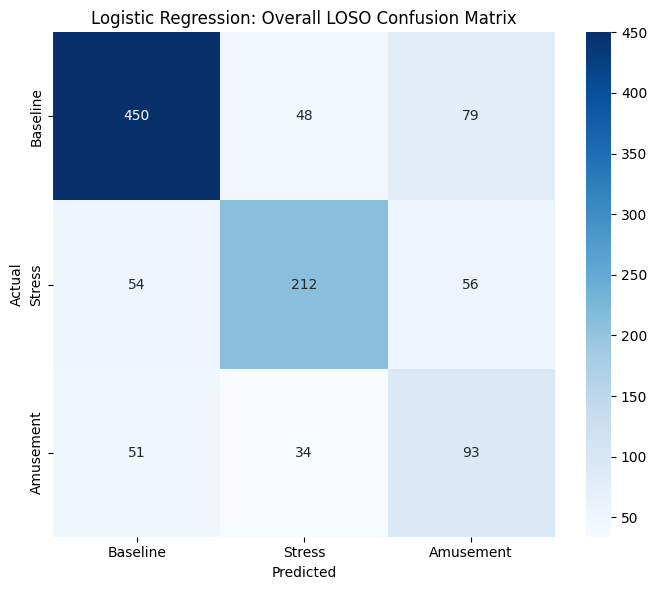

In [27]:
# Cell 26 — Logistic Regression

logistic_model = LogisticRegression(max_iter=2000, C=1.0, random_state=SEED)

logistic_results, logistic_predictions, logistic_summary = evaluate_single_loso_micro(
    model_name="Logistic Regression",
    model=logistic_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: LDA
Fold 01 | Subject S10 | Micro-F1=0.3108 | Balanced Acc=0.3333
Fold 02 | Subject S11 | Micro-F1=0.9452 | Balanced Acc=0.9015
Fold 03 | Subject S13 | Micro-F1=0.6164 | Balanced Acc=0.4242
Fold 04 | Subject S14 | Micro-F1=0.8630 | Balanced Acc=0.8244
Fold 05 | Subject S15 | Micro-F1=0.4795 | Balanced Acc=0.4728
Fold 06 | Subject S16 | Micro-F1=0.8732 | Balanced Acc=0.7690
Fold 07 | Subject S17 | Micro-F1=0.7467 | Balanced Acc=0.7692
Fold 08 | Subject S2 | Micro-F1=0.5652 | Balanced Acc=0.3820
Fold 09 | Subject S3 | Micro-F1=0.7714 | Balanced Acc=0.7053
Fold 10 | Subject S4 | Micro-F1=0.7286 | Balanced Acc=0.5500
Fold 11 | Subject S5 | Micro-F1=0.8472 | Balanced Acc=0.7494
Fold 12 | Subject S6 | Micro-F1=0.9437 | Balanced Acc=0.9388
Fold 13 | Subject S7 | Micro-F1=0.2394 | Balanced Acc=0.3761
Fold 14 | Subject S8 | Micro-F1=0.8451 | Balanced Acc=0.8389
Fold 15 | Subject S9 | Micro-F1=0.6620 | Balanced Acc=0.5613

LDA — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.695827,0.218020
1,Precision Micro,0.695827,0.218020
2,Recall Micro,0.695827,0.218020
3,F1 Micro,0.695827,0.218020
4,Balanced Accuracy,0.639753,0.207000
5,ROC-AUC Micro,0.841104,0.153409



Classification report:
              precision    recall  f1-score   support

    Baseline       0.83      0.79      0.81       577
      Stress       0.73      0.63      0.68       322
   Amusement       0.36      0.50      0.42       178

    accuracy                           0.70      1077
   macro avg       0.64      0.64      0.64      1077
weighted avg       0.72      0.70      0.71      1077



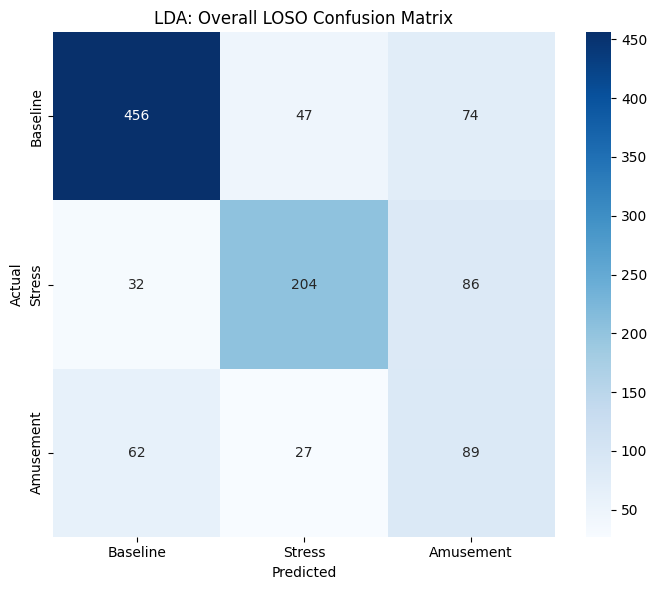

In [28]:
# Cell 27 — LDA

lda_model = LinearDiscriminantAnalysis()

lda_results, lda_predictions, lda_summary = evaluate_single_loso_micro(
    model_name="LDA",
    model=lda_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: KNN
Fold 01 | Subject S10 | Micro-F1=0.7297 | Balanced Acc=0.6189
Fold 02 | Subject S11 | Micro-F1=0.8904 | Balanced Acc=0.8030
Fold 03 | Subject S13 | Micro-F1=0.7534 | Balanced Acc=0.6346
Fold 04 | Subject S14 | Micro-F1=0.7945 | Balanced Acc=0.6915
Fold 05 | Subject S15 | Micro-F1=0.5616 | Balanced Acc=0.4033
Fold 06 | Subject S16 | Micro-F1=0.8310 | Balanced Acc=0.6857
Fold 07 | Subject S17 | Micro-F1=0.7867 | Balanced Acc=0.6111
Fold 08 | Subject S2 | Micro-F1=0.5652 | Balanced Acc=0.3965
Fold 09 | Subject S3 | Micro-F1=0.7571 | Balanced Acc=0.6912
Fold 10 | Subject S4 | Micro-F1=0.5571 | Balanced Acc=0.3579
Fold 11 | Subject S5 | Micro-F1=0.7639 | Balanced Acc=0.5873
Fold 12 | Subject S6 | Micro-F1=0.6197 | Balanced Acc=0.5973
Fold 13 | Subject S7 | Micro-F1=0.6901 | Balanced Acc=0.7927
Fold 14 | Subject S8 | Micro-F1=0.7465 | Balanced Acc=0.5670
Fold 15 | Subject S9 | Micro-F1=0.6338 | Balanced Acc=0.5083

KNN — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.712061,0.103359
1,Precision Micro,0.712061,0.103359
2,Recall Micro,0.712061,0.103359
3,F1 Micro,0.712061,0.103359
4,Balanced Accuracy,0.596428,0.134239
5,ROC-AUC Micro,0.858129,0.077501



Classification report:
              precision    recall  f1-score   support

    Baseline       0.71      0.89      0.79       577
      Stress       0.85      0.63      0.72       322
   Amusement       0.45      0.27      0.34       178

    accuracy                           0.71      1077
   macro avg       0.67      0.60      0.62      1077
weighted avg       0.71      0.71      0.70      1077



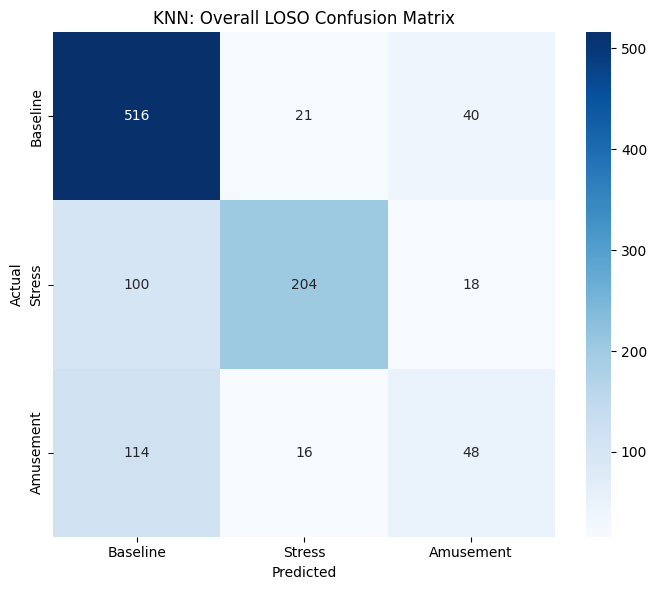

In [29]:
# Cell 28 — KNN

knn_model = KNeighborsClassifier(n_neighbors=7, weights="distance")

knn_results, knn_predictions, knn_summary = evaluate_single_loso_micro(
    model_name="KNN",
    model=knn_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: Gaussian NB
Fold 01 | Subject S10 | Micro-F1=0.6216 | Balanced Acc=0.5383
Fold 02 | Subject S11 | Micro-F1=0.7808 | Balanced Acc=0.7978
Fold 03 | Subject S13 | Micro-F1=0.5753 | Balanced Acc=0.5043
Fold 04 | Subject S14 | Micro-F1=0.7260 | Balanced Acc=0.7059
Fold 05 | Subject S15 | Micro-F1=0.3973 | Balanced Acc=0.5188
Fold 06 | Subject S16 | Micro-F1=0.4789 | Balanced Acc=0.5854
Fold 07 | Subject S17 | Micro-F1=0.6133 | Balanced Acc=0.5235
Fold 08 | Subject S2 | Micro-F1=0.5362 | Balanced Acc=0.3716
Fold 09 | Subject S3 | Micro-F1=0.7857 | Balanced Acc=0.7605
Fold 10 | Subject S4 | Micro-F1=0.6429 | Balanced Acc=0.4895
Fold 11 | Subject S5 | Micro-F1=0.7500 | Balanced Acc=0.6538
Fold 12 | Subject S6 | Micro-F1=0.7887 | Balanced Acc=0.8494
Fold 13 | Subject S7 | Micro-F1=0.6479 | Balanced Acc=0.7863
Fold 14 | Subject S8 | Micro-F1=0.6197 | Balanced Acc=0.6196
Fold 15 | Subject S9 | Micro-F1=0.6479 | Balanced Acc=0.6471

Gaussian NB — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.640821,0.114674
1,Precision Micro,0.640821,0.114674
2,Recall Micro,0.640821,0.114674
3,F1 Micro,0.640821,0.114674
4,Balanced Accuracy,0.623463,0.136347
5,ROC-AUC Micro,0.811809,0.080640



Classification report:
              precision    recall  f1-score   support

    Baseline       0.79      0.68      0.73       577
      Stress       0.78      0.61      0.68       322
   Amusement       0.31      0.58      0.40       178

    accuracy                           0.64      1077
   macro avg       0.63      0.62      0.61      1077
weighted avg       0.71      0.64      0.66      1077



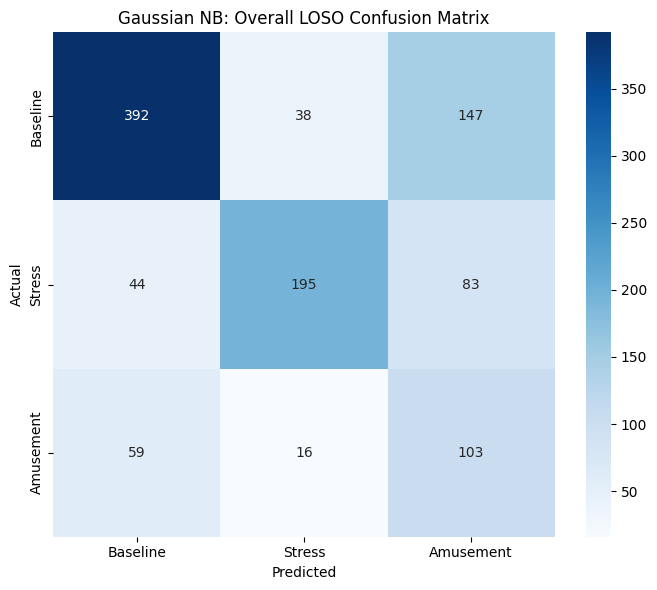

In [30]:
# Cell 29 — Gaussian Naive Bayes

gnb_model = GaussianNB()

gnb_results, gnb_predictions, gnb_summary = evaluate_single_loso_micro(
    model_name="Gaussian NB",
    model=gnb_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: SVM-RBF
Fold 01 | Subject S10 | Micro-F1=0.6216 | Balanced Acc=0.7222
Fold 02 | Subject S11 | Micro-F1=0.9863 | Balanced Acc=0.9722
Fold 03 | Subject S13 | Micro-F1=0.7260 | Balanced Acc=0.5983
Fold 04 | Subject S14 | Micro-F1=0.8356 | Balanced Acc=0.7496
Fold 05 | Subject S15 | Micro-F1=0.6438 | Balanced Acc=0.6342
Fold 06 | Subject S16 | Micro-F1=0.8592 | Balanced Acc=0.7222
Fold 07 | Subject S17 | Micro-F1=0.8533 | Balanced Acc=0.7799
Fold 08 | Subject S2 | Micro-F1=0.5362 | Balanced Acc=0.3333
Fold 09 | Subject S3 | Micro-F1=0.7857 | Balanced Acc=0.7468
Fold 10 | Subject S4 | Micro-F1=0.7143 | Balanced Acc=0.5412
Fold 11 | Subject S5 | Micro-F1=0.8194 | Balanced Acc=0.6581
Fold 12 | Subject S6 | Micro-F1=0.8310 | Balanced Acc=0.8306
Fold 13 | Subject S7 | Micro-F1=0.7746 | Balanced Acc=0.8632
Fold 14 | Subject S8 | Micro-F1=0.7887 | Balanced Acc=0.7329
Fold 15 | Subject S9 | Micro-F1=0.7465 | Balanced Acc=0.6566

SVM-RBF — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.768161,0.110483
1,Precision Micro,0.768161,0.110483
2,Recall Micro,0.768161,0.110483
3,F1 Micro,0.768161,0.110483
4,Balanced Accuracy,0.702764,0.148509
5,ROC-AUC Micro,0.857897,0.131825



Classification report:
              precision    recall  f1-score   support

    Baseline       0.82      0.85      0.83       577
      Stress       0.78      0.79      0.78       322
   Amusement       0.56      0.48      0.52       178

    accuracy                           0.77      1077
   macro avg       0.72      0.70      0.71      1077
weighted avg       0.76      0.77      0.76      1077



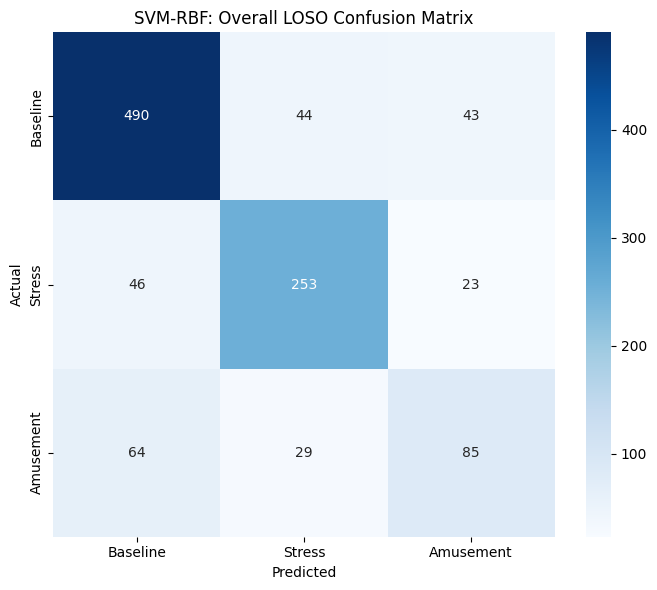

In [31]:
# Cell 30 — SVM-RBF

svm_model = SVC(C=1.0, gamma="scale", probability=True, random_state=SEED)

svm_results, svm_predictions, svm_summary = evaluate_single_loso_micro(
    model_name="SVM-RBF",
    model=svm_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: Decision Tree
Fold 01 | Subject S10 | Micro-F1=0.8514 | Balanced Acc=0.8465
Fold 02 | Subject S11 | Micro-F1=0.7945 | Balanced Acc=0.7234
Fold 03 | Subject S13 | Micro-F1=0.7397 | Balanced Acc=0.5930
Fold 04 | Subject S14 | Micro-F1=0.6027 | Balanced Acc=0.4223
Fold 05 | Subject S15 | Micro-F1=0.5342 | Balanced Acc=0.6109
Fold 06 | Subject S16 | Micro-F1=0.6620 | Balanced Acc=0.6067
Fold 07 | Subject S17 | Micro-F1=0.7867 | Balanced Acc=0.6603
Fold 08 | Subject S2 | Micro-F1=0.7101 | Balanced Acc=0.7329
Fold 09 | Subject S3 | Micro-F1=0.6429 | Balanced Acc=0.5596
Fold 10 | Subject S4 | Micro-F1=0.6000 | Balanced Acc=0.4000
Fold 11 | Subject S5 | Micro-F1=0.6806 | Balanced Acc=0.5846
Fold 12 | Subject S6 | Micro-F1=0.7887 | Balanced Acc=0.6594
Fold 13 | Subject S7 | Micro-F1=0.7465 | Balanced Acc=0.7145
Fold 14 | Subject S8 | Micro-F1=0.3521 | Balanced Acc=0.2831
Fold 15 | Subject S9 | Micro-F1=0.7324 | Balanced Acc=0.5763

Decision Tree — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.681633,0.125387
1,Precision Micro,0.681633,0.125387
2,Recall Micro,0.681633,0.125387
3,F1 Micro,0.681633,0.125387
4,Balanced Accuracy,0.598235,0.143559
5,ROC-AUC Micro,0.794146,0.097193



Classification report:
              precision    recall  f1-score   support

    Baseline       0.78      0.79      0.79       577
      Stress       0.72      0.70      0.71       322
   Amusement       0.30      0.31      0.31       178

    accuracy                           0.68      1077
   macro avg       0.60      0.60      0.60      1077
weighted avg       0.68      0.68      0.68      1077



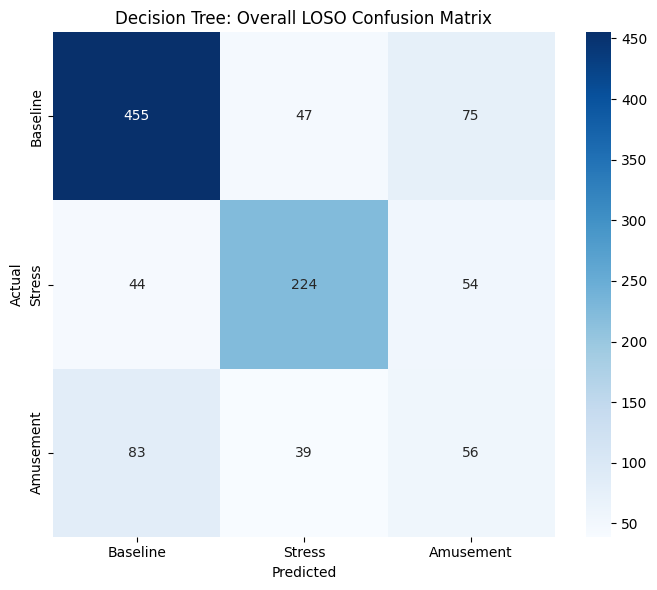

In [32]:
# Cell 31 — Decision Tree

dt_model = DecisionTreeClassifier(max_depth=10, min_samples_leaf=3, random_state=SEED)

dt_results, dt_predictions, dt_summary = evaluate_single_loso_micro(
    model_name="Decision Tree",
    model=dt_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: Random Forest
Fold 01 | Subject S10 | Micro-F1=0.8919 | Balanced Acc=0.7970
Fold 02 | Subject S11 | Micro-F1=0.8904 | Balanced Acc=0.7778
Fold 03 | Subject S13 | Micro-F1=0.8219 | Balanced Acc=0.6515
Fold 04 | Subject S14 | Micro-F1=0.6849 | Balanced Acc=0.5000
Fold 05 | Subject S15 | Micro-F1=0.7945 | Balanced Acc=0.7348
Fold 06 | Subject S16 | Micro-F1=0.8310 | Balanced Acc=0.6667
Fold 07 | Subject S17 | Micro-F1=0.8400 | Balanced Acc=0.7244
Fold 08 | Subject S2 | Micro-F1=0.6957 | Balanced Acc=0.5611
Fold 09 | Subject S3 | Micro-F1=0.6571 | Balanced Acc=0.5892
Fold 10 | Subject S4 | Micro-F1=0.6143 | Balanced Acc=0.4167
Fold 11 | Subject S5 | Micro-F1=0.8056 | Balanced Acc=0.6496
Fold 12 | Subject S6 | Micro-F1=0.8028 | Balanced Acc=0.6681
Fold 13 | Subject S7 | Micro-F1=0.9014 | Balanced Acc=0.8825
Fold 14 | Subject S8 | Micro-F1=0.7465 | Balanced Acc=0.7002
Fold 15 | Subject S9 | Micro-F1=0.9577 | Balanced Acc=0.9524

Random Forest — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.795716,0.098746
1,Precision Micro,0.795716,0.098746
2,Recall Micro,0.795716,0.098746
3,F1 Micro,0.795716,0.098746
4,Balanced Accuracy,0.684794,0.138783
5,ROC-AUC Micro,0.929920,0.044141



Classification report:
              precision    recall  f1-score   support

    Baseline       0.80      0.94      0.86       577
      Stress       0.83      0.82      0.83       322
   Amusement       0.62      0.30      0.40       178

    accuracy                           0.80      1077
   macro avg       0.75      0.69      0.70      1077
weighted avg       0.78      0.80      0.78      1077



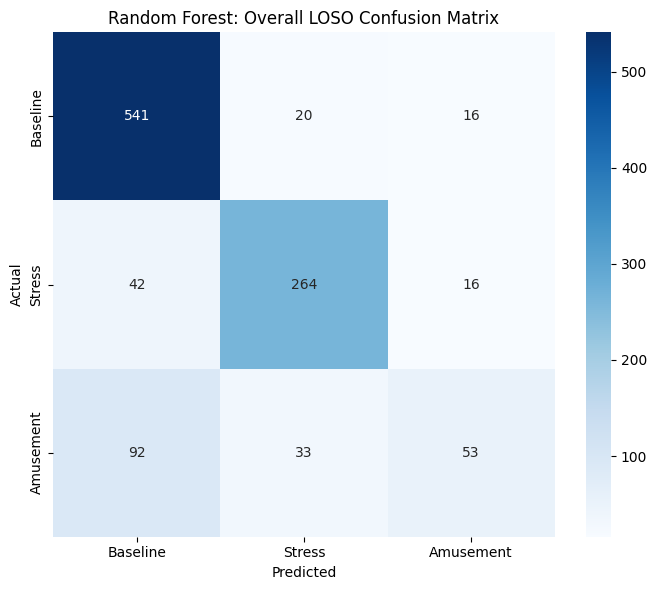

In [33]:
# Cell 32 — Random Forest

rf_model = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=2, random_state=SEED, n_jobs=-1)

rf_results, rf_predictions, rf_summary = evaluate_single_loso_micro(
    model_name="Random Forest",
    model=rf_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: Extra Trees
Fold 01 | Subject S10 | Micro-F1=0.8514 | Balanced Acc=0.6944
Fold 02 | Subject S11 | Micro-F1=0.8767 | Balanced Acc=0.7500
Fold 03 | Subject S13 | Micro-F1=0.7808 | Balanced Acc=0.6325
Fold 04 | Subject S14 | Micro-F1=0.9178 | Balanced Acc=0.8460
Fold 05 | Subject S15 | Micro-F1=0.7945 | Balanced Acc=0.7348
Fold 06 | Subject S16 | Micro-F1=0.8732 | Balanced Acc=0.7500
Fold 07 | Subject S17 | Micro-F1=0.8133 | Balanced Acc=0.6496
Fold 08 | Subject S2 | Micro-F1=0.6522 | Balanced Acc=0.4667
Fold 09 | Subject S3 | Micro-F1=0.6857 | Balanced Acc=0.5628
Fold 10 | Subject S4 | Micro-F1=0.5857 | Balanced Acc=0.3833
Fold 11 | Subject S5 | Micro-F1=0.8333 | Balanced Acc=0.6667
Fold 12 | Subject S6 | Micro-F1=0.8028 | Balanced Acc=0.6871
Fold 13 | Subject S7 | Micro-F1=0.8169 | Balanced Acc=0.7543
Fold 14 | Subject S8 | Micro-F1=0.8310 | Balanced Acc=0.6515
Fold 15 | Subject S9 | Micro-F1=0.9718 | Balanced Acc=0.9683

Extra Trees — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.805817,0.100198
1,Precision Micro,0.805817,0.100198
2,Recall Micro,0.805817,0.100198
3,F1 Micro,0.805817,0.100198
4,Balanced Accuracy,0.679866,0.141582
5,ROC-AUC Micro,0.934009,0.052184



Classification report:
              precision    recall  f1-score   support

    Baseline       0.80      0.96      0.87       577
      Stress       0.82      0.85      0.84       322
   Amusement       0.76      0.23      0.35       178

    accuracy                           0.81      1077
   macro avg       0.80      0.68      0.69      1077
weighted avg       0.80      0.81      0.78      1077



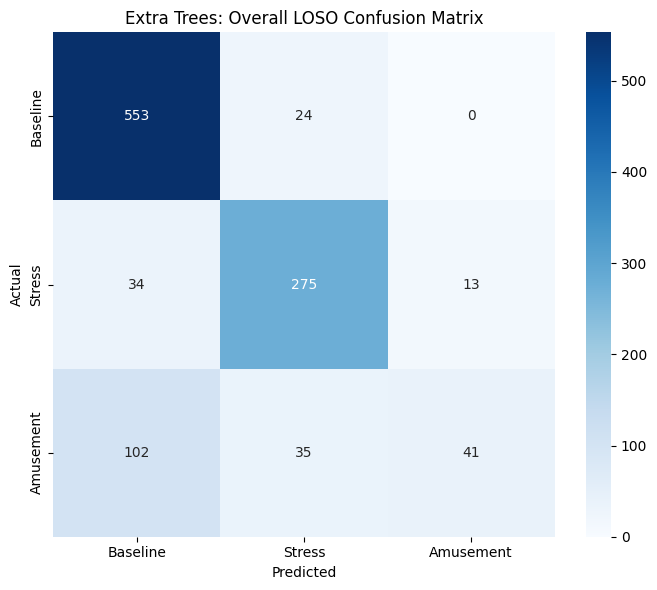

In [34]:
# Cell 33 — Extra Trees

extra_trees_model = ExtraTreesClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=2, random_state=SEED, n_jobs=-1)

extra_trees_results, extra_trees_predictions, extra_trees_summary = evaluate_single_loso_micro(
    model_name="Extra Trees",
    model=extra_trees_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)

Running: XGBoost
Fold 01 | Subject S10 | Micro-F1=0.8108 | Balanced Acc=0.6496
Fold 02 | Subject S11 | Micro-F1=0.9315 | Balanced Acc=0.8611
Fold 03 | Subject S13 | Micro-F1=0.7808 | Balanced Acc=0.6193
Fold 04 | Subject S14 | Micro-F1=0.7808 | Balanced Acc=0.6818
Fold 05 | Subject S15 | Micro-F1=0.6712 | Balanced Acc=0.7090
Fold 06 | Subject S16 | Micro-F1=0.8310 | Balanced Acc=0.6667
Fold 07 | Subject S17 | Micro-F1=0.8133 | Balanced Acc=0.6496
Fold 08 | Subject S2 | Micro-F1=0.6522 | Balanced Acc=0.4667
Fold 09 | Subject S3 | Micro-F1=0.7714 | Balanced Acc=0.7533
Fold 10 | Subject S4 | Micro-F1=0.5571 | Balanced Acc=0.3500
Fold 11 | Subject S5 | Micro-F1=0.8056 | Balanced Acc=0.6422
Fold 12 | Subject S6 | Micro-F1=0.8451 | Balanced Acc=0.7325
Fold 13 | Subject S7 | Micro-F1=0.9155 | Balanced Acc=0.9295
Fold 14 | Subject S8 | Micro-F1=0.8451 | Balanced Acc=0.6667
Fold 15 | Subject S9 | Micro-F1=0.9859 | Balanced Acc=0.9697

XGBoost — FINAL LOSO MICRO-AVERAGED RESULTS


,Metric,Mean,Std
0,Accuracy,0.799824,0.110036
1,Precision Micro,0.799824,0.110036
2,Recall Micro,0.799824,0.110036
3,F1 Micro,0.799824,0.110036
4,Balanced Accuracy,0.689838,0.157712
5,ROC-AUC Micro,0.917237,0.065735



Classification report:
              precision    recall  f1-score   support

    Baseline       0.80      0.94      0.87       577
      Stress       0.85      0.81      0.83       322
   Amusement       0.61      0.32      0.42       178

    accuracy                           0.80      1077
   macro avg       0.76      0.69      0.71      1077
weighted avg       0.79      0.80      0.78      1077



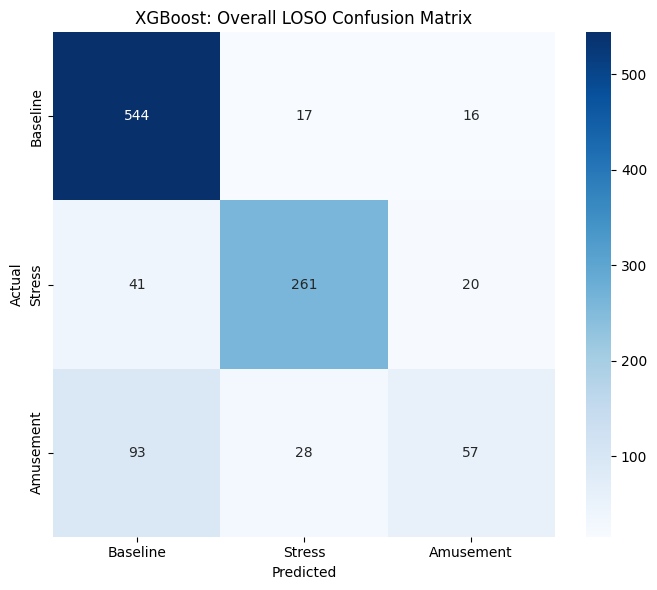

In [35]:
# Cell 34 — XGBoost baseline

xgb_model = XGBClassifier(n_estimators=250, max_depth=5, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85, objective="multi:softprob", num_class=3, eval_metric="mlogloss", random_state=SEED, n_jobs=2)

xgb_results, xgb_predictions, xgb_summary = evaluate_single_loso_micro(
    model_name="XGBoost",
    model=xgb_model,
    X=X_all,
    y=y_all,
    groups=groups_all,
    use_pca=False
)


## 9. Baseline model comparison

The primary ranking uses **mean Micro-F1**. Balanced accuracy and the standard deviation across LOSO folds are retained to assess class-balanced performance and stability.


In [36]:

# Cell 35 — Overall micro-score comparison

model_summaries = {
    "Logistic Regression": logistic_summary,
    "LDA": lda_summary,
    "KNN": knn_summary,
    "Gaussian NB": gnb_summary,
    "SVM-RBF": svm_summary,
    "Decision Tree": dt_summary,
    "Random Forest": rf_summary,
    "Extra Trees": extra_trees_summary,
    "XGBoost": xgb_summary
}

comparison_rows = []
for model_name, s in model_summaries.items():
    row = {"Model": model_name}
    for _, r in s.iterrows():
        row[f"{r['Metric']} Mean"] = r["Mean"]
        row[f"{r['Metric']} SD"] = r["Std"]
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    "F1 Micro Mean", ascending=False
).reset_index(drop=True)

display(comparison_df)
comparison_df.to_csv(RESULTS_DIR / "micro_model_comparison.csv", index=False)


,Model,Accuracy Mean,Accuracy SD,Precision Micro Mean,Precision Micro SD,Recall Micro Mean,Recall Micro SD,F1 Micro Mean,F1 Micro SD,Balanced Accuracy Mean,Balanced Accuracy SD,ROC-AUC Micro Mean,ROC-AUC Micro SD
0,Extra Trees,0.805817,0.100198,0.805817,0.100198,0.805817,0.100198,0.805817,0.100198,0.679866,0.141582,0.934009,0.052184
1,XGBoost,0.799824,0.110036,0.799824,0.110036,0.799824,0.110036,0.799824,0.110036,0.689838,0.157712,0.917237,0.065735
2,Random Forest,0.795716,0.098746,0.795716,0.098746,0.795716,0.098746,0.795716,0.098746,0.684794,0.138783,0.929920,0.044141
3,SVM-RBF,0.768161,0.110483,0.768161,0.110483,0.768161,0.110483,0.768161,0.110483,0.702764,0.148509,0.857897,0.131825
4,KNN,0.712061,0.103359,0.712061,0.103359,0.712061,0.103359,0.712061,0.103359,0.596428,0.134239,0.858129,0.077501
5,Logistic Regression,0.701575,0.188076,0.701575,0.188076,0.701575,0.188076,0.701575,0.188076,0.652846,0.177747,0.834712,0.141432
6,LDA,0.695827,0.218020,0.695827,0.218020,0.695827,0.218020,0.695827,0.218020,0.639753,0.207000,0.841104,0.153409
7,Decision Tree,0.681633,0.125387,0.681633,0.125387,0.681633,0.125387,0.681633,0.125387,0.598235,0.143559,0.794146,0.097193
8,Gaussian NB,0.640821,0.114674,0.640821,0.114674,0.640821,0.114674,0.640821,0.114674,0.623463,0.136347,0.811809,0.080640


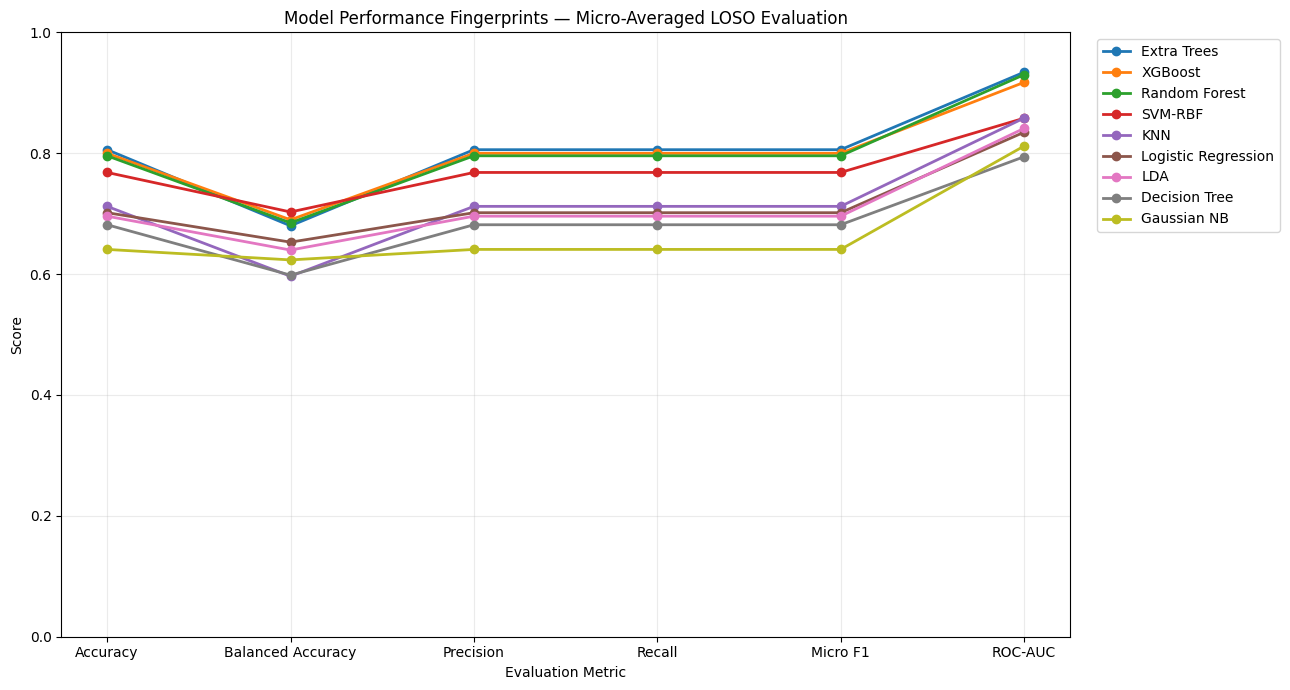

In [37]:

# Cell 36 — Creative graph: model performance fingerprint

metrics = [
    "Accuracy Mean",
    "Balanced Accuracy Mean",
    "Precision Micro Mean",
    "Recall Micro Mean",
    "F1 Micro Mean",
    "ROC-AUC Micro Mean"
]
labels = ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "Micro F1", "ROC-AUC"]

plt.figure(figsize=(13, 7))
for _, row in comparison_df.iterrows():
    plt.plot(labels, [row[m] for m in metrics], marker="o", linewidth=2, label=row["Model"])
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.title("Model Performance Fingerprints — Micro-Averaged LOSO Evaluation")
plt.grid(alpha=0.25)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_performance_fingerprints_micro.png", dpi=300, bbox_inches="tight")
plt.show()


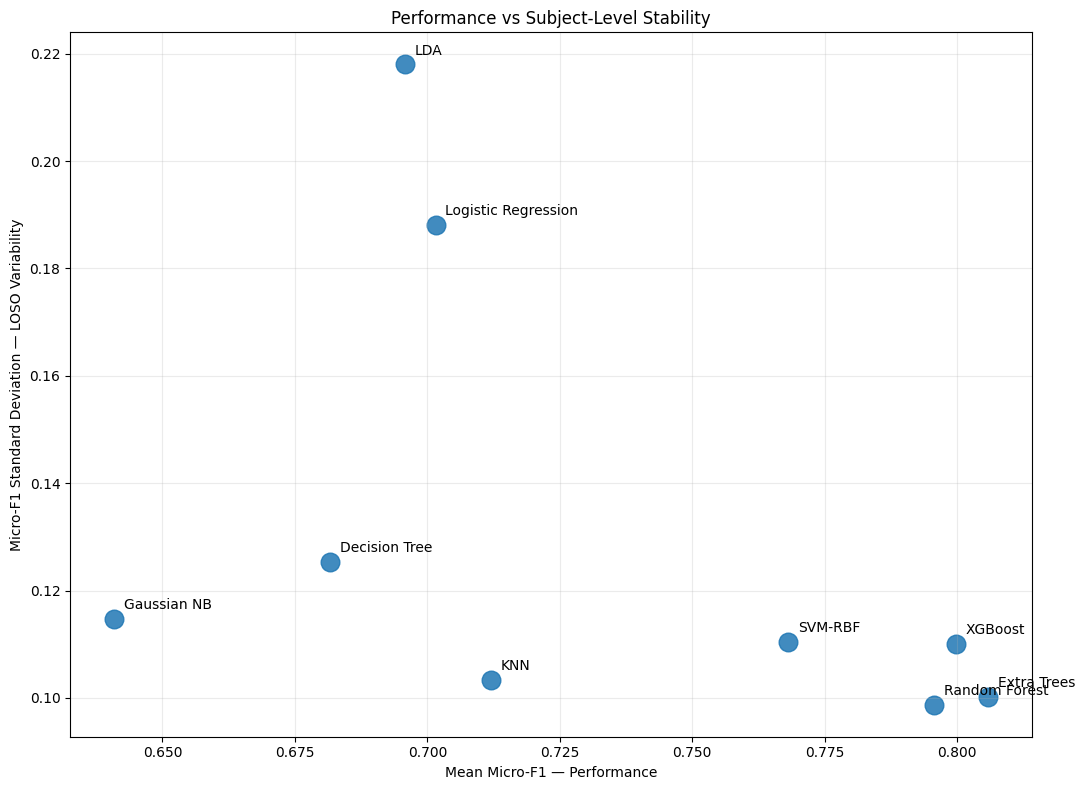

In [38]:

# Cell 37 — Creative graph: performance versus stability

plt.figure(figsize=(11, 8))
plt.scatter(comparison_df["F1 Micro Mean"], comparison_df["F1 Micro SD"], s=180, alpha=0.85)
for _, row in comparison_df.iterrows():
    plt.annotate(row["Model"], (row["F1 Micro Mean"], row["F1 Micro SD"]), xytext=(7, 7), textcoords="offset points")
plt.xlabel("Mean Micro-F1 — Performance")
plt.ylabel("Micro-F1 Standard Deviation — LOSO Variability")
plt.title("Performance vs Subject-Level Stability")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "performance_vs_stability_micro.png", dpi=300, bbox_inches="tight")
plt.show()



# 10. XGBoost fine-tuning

XGBoost is fine-tuned using **nested subject-aware validation**. For every outer LOSO test subject, hyperparameters are selected using only the remaining training subjects with an inner `GroupKFold`. The tuning objective is **Micro-F1**, matching the primary evaluation metric. This prevents the held-out subject from influencing hyperparameter selection.

The search is intentionally compact so the notebook remains practical in Google Colab. Increase `N_ITER_TUNING` if more computational time is available.


In [39]:

# Cell 38 — Leakage-safe nested XGBoost fine-tuning

N_ITER_TUNING = 8
INNER_FOLDS = 3

XGB_PARAM_DISTRIBUTIONS = {
    "model__n_estimators": [150, 200, 250, 300],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.03, 0.05, 0.08, 0.10],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.75, 0.85, 1.0],
    "model__colsample_bytree": [0.75, 0.85, 1.0],
    "model__gamma": [0, 0.1, 0.3]
}


def tune_xgboost_loso(X, y, groups):
    outer_logo = LeaveOneGroupOut()
    rows = []
    all_predictions = []
    best_params_by_fold = []

    for fold, (train_idx, test_idx) in enumerate(outer_logo.split(X, y, groups), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        groups_train = groups.iloc[train_idx]
        test_subject = groups.iloc[test_idx].iloc[0]

        base_xgb = XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            eval_metric="mlogloss",
            random_state=SEED,
            n_jobs=2,
            tree_method="hist"
        )

        tune_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", base_xgb)
        ])

        inner_cv = GroupKFold(n_splits=min(INNER_FOLDS, groups_train.nunique()))

        search = RandomizedSearchCV(
            estimator=tune_pipe,
            param_distributions=XGB_PARAM_DISTRIBUTIONS,
            n_iter=N_ITER_TUNING,
            scoring="f1_micro",
            cv=inner_cv,
            random_state=SEED + fold,
            n_jobs=1,
            refit=True,
            verbose=0
        )

        y_train_fit = y_train - 1
        search.fit(X_train, y_train_fit, groups=groups_train)

        best_pipe = search.best_estimator_
        pred = best_pipe.predict(X_test).astype(int) + 1

        metrics = calculate_micro_metrics(y_test, pred)
        roc_auc = np.nan
        try:
            proba = best_pipe.predict_proba(X_test)
            y_bin = label_binarize(y_test, classes=CLASS_ORDER)
            roc_auc = roc_auc_score(y_bin, proba, multi_class="ovr", average="micro")
        except Exception:
            pass

        rows.append({
            "model": "XGBoost Tuned",
            "fold": fold,
            "test_subject": test_subject,
            **metrics,
            "roc_auc_micro": roc_auc,
            "inner_best_micro_f1": search.best_score_
        })

        best_params_by_fold.append({
            "fold": fold,
            "test_subject": test_subject,
            "inner_best_micro_f1": search.best_score_,
            **search.best_params_
        })

        for i, p in zip(test_idx, pred):
            all_predictions.append({
                "subject": groups.iloc[i],
                "true": int(y.iloc[i]),
                "pred": int(p)
            })

        print(
            f"Fold {fold:02d} | Subject {test_subject} | "
            f"Inner Micro-F1={search.best_score_:.4f} | "
            f"Outer Micro-F1={metrics['f1_micro']:.4f}"
        )

    tuned_results = pd.DataFrame(rows)
    tuned_predictions = pd.DataFrame(all_predictions)
    tuned_params = pd.DataFrame(best_params_by_fold)

    tuned_summary = pd.DataFrame({
        "Metric": [
            "Accuracy", "Precision Micro", "Recall Micro", "F1 Micro",
            "Balanced Accuracy", "ROC-AUC Micro"
        ],
        "Mean": [
            tuned_results["accuracy"].mean(),
            tuned_results["precision_micro"].mean(),
            tuned_results["recall_micro"].mean(),
            tuned_results["f1_micro"].mean(),
            tuned_results["balanced_accuracy"].mean(),
            tuned_results["roc_auc_micro"].mean()
        ],
        "Std": [
            tuned_results["accuracy"].std(),
            tuned_results["precision_micro"].std(),
            tuned_results["recall_micro"].std(),
            tuned_results["f1_micro"].std(),
            tuned_results["balanced_accuracy"].std(),
            tuned_results["roc_auc_micro"].std()
        ]
    })

    return tuned_results, tuned_predictions, tuned_summary, tuned_params


In [40]:

# Cell 39 — Run nested XGBoost fine-tuning

tuned_xgb_results, tuned_xgb_predictions, tuned_xgb_summary, tuned_xgb_params = tune_xgboost_loso(
    X_all,
    y_all,
    groups_all
)

display(tuned_xgb_summary)
display(tuned_xgb_params)

tuned_xgb_results.to_csv(RESULTS_DIR / "xgboost_tuned_loso_results.csv", index=False)
tuned_xgb_params.to_csv(RESULTS_DIR / "xgboost_tuned_parameters_by_fold.csv", index=False)


Fold 01 | Subject S10 | Inner Micro-F1=0.7545 | Outer Micro-F1=0.8243
Fold 02 | Subject S11 | Inner Micro-F1=0.7506 | Outer Micro-F1=0.9863
Fold 03 | Subject S13 | Inner Micro-F1=0.7696 | Outer Micro-F1=0.7671
Fold 04 | Subject S14 | Inner Micro-F1=0.7360 | Outer Micro-F1=0.7397
Fold 05 | Subject S15 | Inner Micro-F1=0.7501 | Outer Micro-F1=0.6438
Fold 06 | Subject S16 | Inner Micro-F1=0.7496 | Outer Micro-F1=0.8310
Fold 07 | Subject S17 | Inner Micro-F1=0.6839 | Outer Micro-F1=0.8133
Fold 08 | Subject S2 | Inner Micro-F1=0.7662 | Outer Micro-F1=0.6522
Fold 09 | Subject S3 | Inner Micro-F1=0.7400 | Outer Micro-F1=0.7571
Fold 10 | Subject S4 | Inner Micro-F1=0.7450 | Outer Micro-F1=0.5429
Fold 11 | Subject S5 | Inner Micro-F1=0.7594 | Outer Micro-F1=0.8194
Fold 12 | Subject S6 | Inner Micro-F1=0.7010 | Outer Micro-F1=0.8451
Fold 13 | Subject S7 | Inner Micro-F1=0.6645 | Outer Micro-F1=0.9296
Fold 14 | Subject S8 | Inner Micro-F1=0.6797 | Outer Micro-F1=0.8451
Fold 15 | Subject S9 | Inne

,Metric,Mean,Std
0,Accuracy,0.798859,0.122803
1,Precision Micro,0.798859,0.122803
2,Recall Micro,0.798859,0.122803
3,F1 Micro,0.798859,0.122803
4,Balanced Accuracy,0.692114,0.171438
5,ROC-AUC Micro,0.917124,0.066282


,fold,test_subject,inner_best_micro_f1,model__subsample,model__n_estimators,model__min_child_weight,model__max_depth,model__learning_rate,model__gamma,model__colsample_bytree
0,1,S10,0.754493,0.85,250,1,4,0.10,0.0,1.00
1,2,S11,0.750561,0.85,250,5,4,0.03,0.3,0.85
2,3,S13,0.769635,0.85,250,3,3,0.05,0.0,0.75
3,4,S14,0.736024,0.75,150,3,6,0.05,0.3,0.85
4,5,S15,0.750103,0.75,300,5,6,0.08,0.1,0.85
5,6,S16,0.749567,0.85,300,3,3,0.10,0.0,0.75
6,7,S17,0.683931,0.75,250,5,6,0.08,0.0,0.75
7,8,S2,0.766158,0.85,250,1,5,0.08,0.0,0.75
8,9,S3,0.739962,1.00,200,3,4,0.10,0.0,0.75
9,10,S4,0.745010,0.75,150,1,6,0.10,0.3,0.75


,Version,Micro-F1,Balanced Accuracy
0,Baseline XGBoost,0.799824,0.689838
1,Fine-tuned XGBoost,0.798859,0.692114


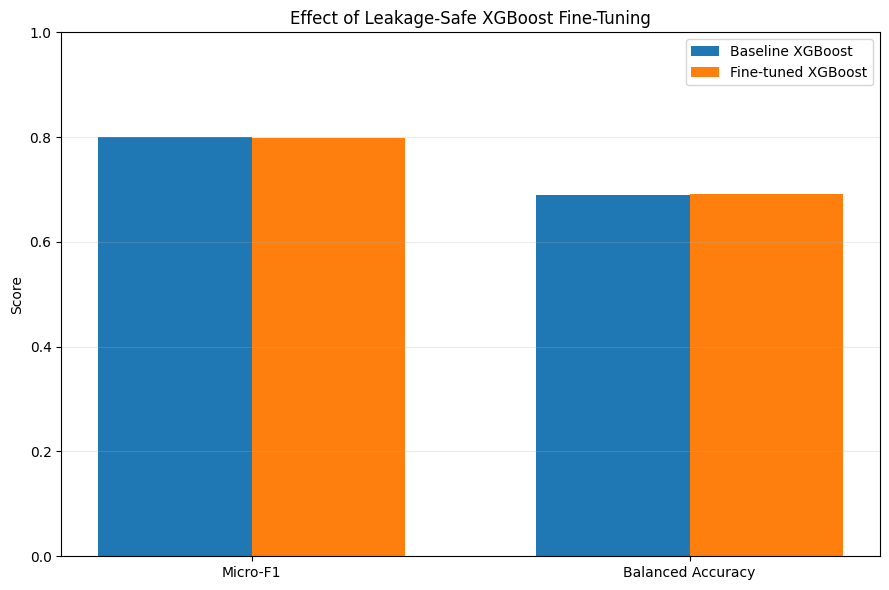

In [41]:

# Cell 40 — Baseline XGBoost vs tuned XGBoost

baseline_f1 = xgb_summary.loc[xgb_summary["Metric"] == "F1 Micro", "Mean"].iloc[0]
tuned_f1 = tuned_xgb_summary.loc[tuned_xgb_summary["Metric"] == "F1 Micro", "Mean"].iloc[0]

baseline_bal = xgb_summary.loc[xgb_summary["Metric"] == "Balanced Accuracy", "Mean"].iloc[0]
tuned_bal = tuned_xgb_summary.loc[tuned_xgb_summary["Metric"] == "Balanced Accuracy", "Mean"].iloc[0]

fine_tuning_comparison = pd.DataFrame({
    "Version": ["Baseline XGBoost", "Fine-tuned XGBoost"],
    "Micro-F1": [baseline_f1, tuned_f1],
    "Balanced Accuracy": [baseline_bal, tuned_bal]
})

display(fine_tuning_comparison)

plt.figure(figsize=(9, 6))
plot_cols = ["Micro-F1", "Balanced Accuracy"]
x = np.arange(len(plot_cols))
width = 0.35
plt.bar(x - width/2, fine_tuning_comparison.iloc[0][plot_cols].values, width, label="Baseline XGBoost")
plt.bar(x + width/2, fine_tuning_comparison.iloc[1][plot_cols].values, width, label="Fine-tuned XGBoost")
plt.xticks(x, plot_cols)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Effect of Leakage-Safe XGBoost Fine-Tuning")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "xgboost_baseline_vs_tuned_micro.png", dpi=300, bbox_inches="tight")
plt.show()


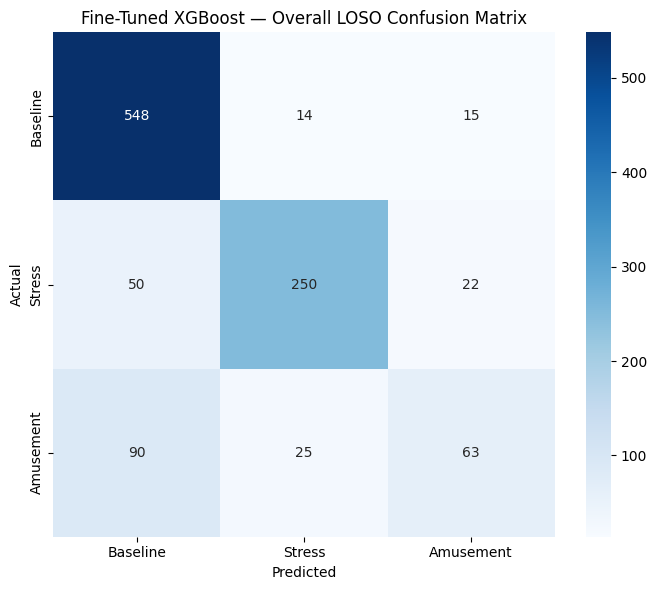

              precision    recall  f1-score   support

    Baseline       0.80      0.95      0.87       577
      Stress       0.87      0.78      0.82       322
   Amusement       0.63      0.35      0.45       178

    accuracy                           0.80      1077
   macro avg       0.76      0.69      0.71      1077
weighted avg       0.79      0.80      0.78      1077



In [42]:

# Cell 41 — Fine-tuned XGBoost confusion matrix and classification report

cm_tuned = confusion_matrix(
    tuned_xgb_predictions["true"],
    tuned_xgb_predictions["pred"],
    labels=CLASS_ORDER
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[LABEL_MAP[i] for i in CLASS_ORDER],
    yticklabels=[LABEL_MAP[i] for i in CLASS_ORDER]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fine-Tuned XGBoost — Overall LOSO Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "xgboost_tuned_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(classification_report(
    tuned_xgb_predictions["true"],
    tuned_xgb_predictions["pred"],
    labels=CLASS_ORDER,
    target_names=[LABEL_MAP[i] for i in CLASS_ORDER],
    zero_division=0
))


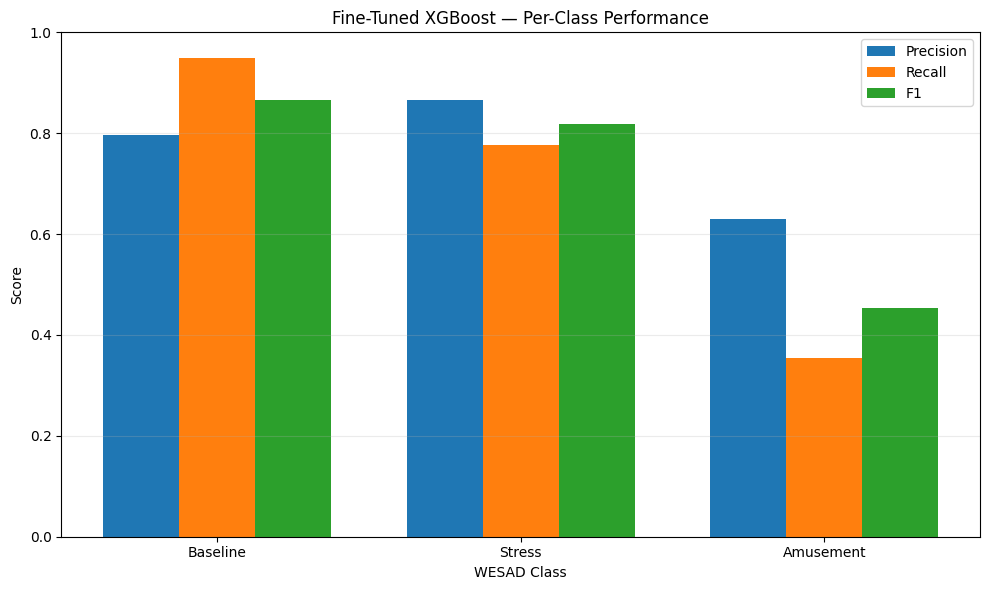

In [43]:

# Cell 42 — Fine-tuned XGBoost per-class performance

from sklearn.metrics import precision_recall_fscore_support

p, r, f, s = precision_recall_fscore_support(
    tuned_xgb_predictions["true"],
    tuned_xgb_predictions["pred"],
    labels=CLASS_ORDER,
    zero_division=0
)

class_names = [LABEL_MAP[i] for i in CLASS_ORDER]
x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - width, p, width, label="Precision")
plt.bar(x, r, width, label="Recall")
plt.bar(x + width, f, width, label="F1")
plt.xticks(x, class_names)
plt.ylim(0, 1)
plt.xlabel("WESAD Class")
plt.ylabel("Score")
plt.title("Fine-Tuned XGBoost — Per-Class Performance")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "xgboost_tuned_per_class.png", dpi=300, bbox_inches="tight")
plt.show()


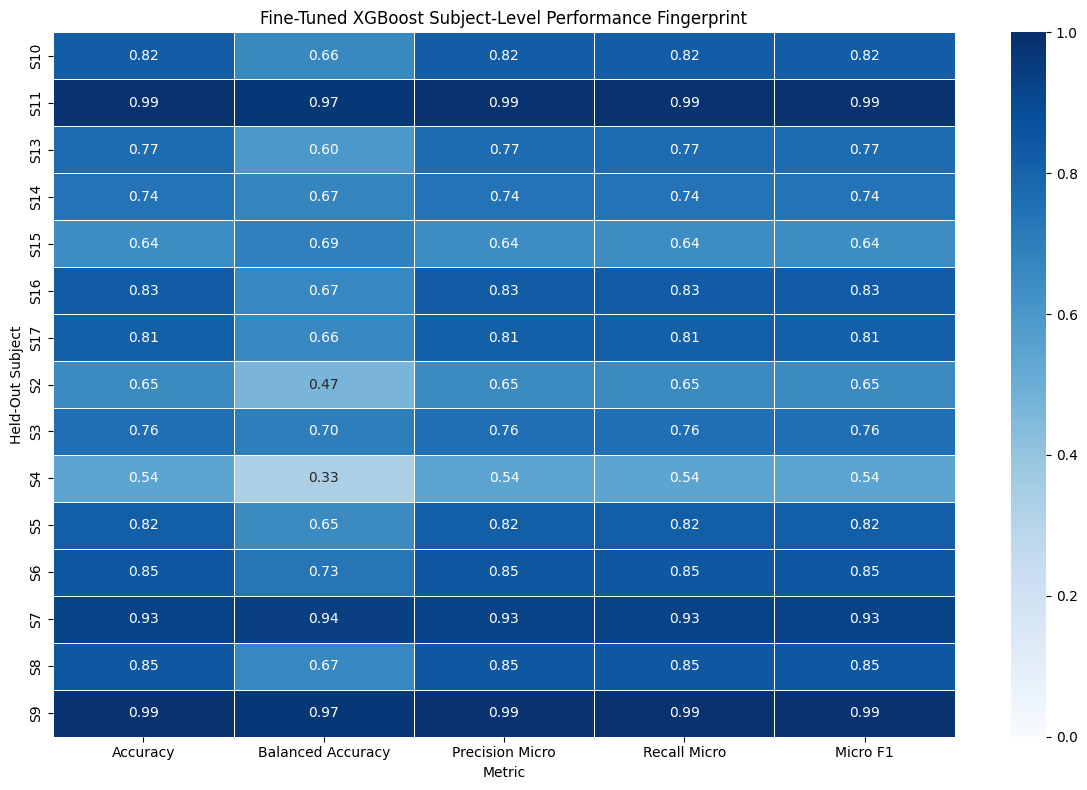

In [44]:

# Cell 43 — Fine-tuned XGBoost subject-level stability heatmap

subject_metrics = tuned_xgb_results[
    ["test_subject", "accuracy", "balanced_accuracy", "precision_micro", "recall_micro", "f1_micro"]
].copy().set_index("test_subject")
subject_metrics.columns = ["Accuracy", "Balanced Accuracy", "Precision Micro", "Recall Micro", "Micro F1"]

plt.figure(figsize=(12, 8))
sns.heatmap(subject_metrics, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=0.5)
plt.xlabel("Metric")
plt.ylabel("Held-Out Subject")
plt.title("Fine-Tuned XGBoost Subject-Level Performance Fingerprint")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "xgboost_tuned_subject_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


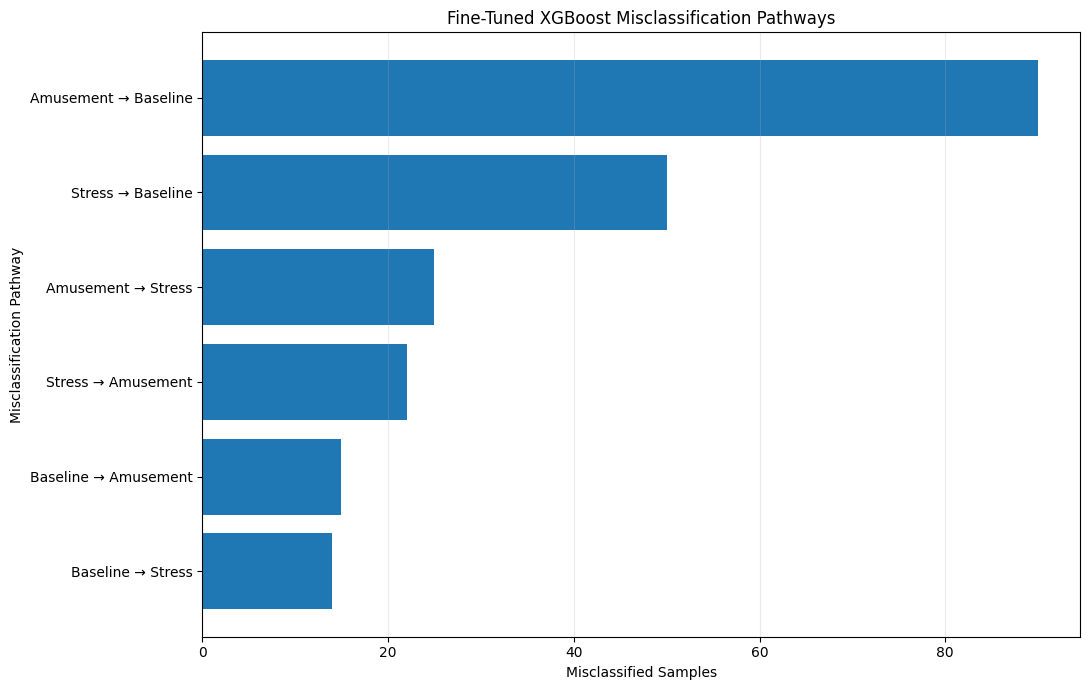

In [45]:

# Cell 44 — XGBoost misclassification pathways

cm = confusion_matrix(tuned_xgb_predictions["true"], tuned_xgb_predictions["pred"], labels=CLASS_ORDER)
confusion_pairs = []
for i, actual in enumerate(CLASS_ORDER):
    for j, predicted in enumerate(CLASS_ORDER):
        if i != j:
            confusion_pairs.append({
                "Path": f"{LABEL_MAP[actual]} → {LABEL_MAP[predicted]}",
                "Count": int(cm[i, j])
            })

confusion_pairs = pd.DataFrame(confusion_pairs).sort_values("Count", ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(confusion_pairs["Path"], confusion_pairs["Count"])
plt.xlabel("Misclassified Samples")
plt.ylabel("Misclassification Pathway")
plt.title("Fine-Tuned XGBoost Misclassification Pathways")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "xgboost_tuned_misclassification_pathways.png", dpi=300, bbox_inches="tight")
plt.show()


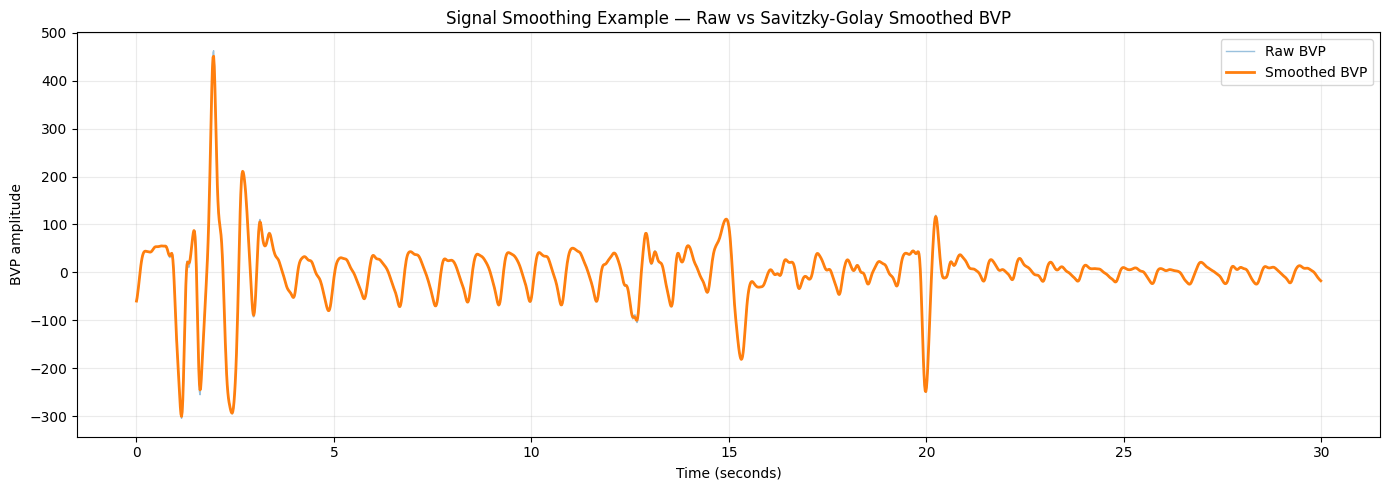

In [46]:

# Cell 45 — Raw vs smoothed signal example for the report

raw_bvp = get_sensor_window(sample_data["signal"]["wrist"]["BVP"], 0, 30, 64, smooth=False)
smoothed_bvp = smooth_signal(raw_bvp, 64, enabled=True)
time_axis = np.arange(len(raw_bvp)) / 64.0

plt.figure(figsize=(14, 5))
plt.plot(time_axis, raw_bvp, linewidth=1, alpha=0.45, label="Raw BVP")
plt.plot(time_axis, smoothed_bvp, linewidth=2, label="Smoothed BVP")
plt.xlabel("Time (seconds)")
plt.ylabel("BVP amplitude")
plt.title("Signal Smoothing Example — Raw vs Savitzky-Golay Smoothed BVP")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "signal_smoothing_raw_vs_smoothed.png", dpi=300, bbox_inches="tight")
plt.show()



# 11. Final interpretation guidance

Use **Micro-F1 as the primary headline score** because this was requested for the experiment. However, do not describe it as class-balanced: in this single-label three-class problem, micro precision, micro recall and micro F1 are equivalent to overall accuracy. Use **balanced accuracy, per-class precision/recall/F1, the confusion matrix and LOSO standard deviation** to support the conclusion.

For the final report, compare:

1. all baseline algorithms;
2. baseline XGBoost versus fine-tuned XGBoost;
3. subject-level stability;
4. class-specific errors; and
5. the effect of smoothing.

Do not claim that fine-tuning improved performance unless the measured outer-LOSO Micro-F1 actually increases. Because tuning is nested inside the training subjects, the outer test subjects remain unseen during model selection.


In [47]:

# # Cell 46 — Save the complete result tables

# comparison_df.to_csv(RESULTS_DIR / "final_model_comparison_micro.csv", index=False)
# tuned_xgb_summary.to_csv(RESULTS_DIR / "final_tuned_xgboost_summary_micro.csv", index=False)

# print("All result files and report figures have been saved to:")
# print(RESULTS_DIR)
# print("\nGenerated figures include:")
# for p in sorted(RESULTS_DIR.glob("*.png")):
#     print(" -", p.name)


All result files and report figures have been saved to:
/content/wesad_results

Generated figures include:
 - model_performance_fingerprints_micro.png
 - performance_vs_stability_micro.png
 - signal_smoothing_raw_vs_smoothed.png
 - xgboost_baseline_vs_tuned_micro.png
 - xgboost_tuned_confusion_matrix.png
 - xgboost_tuned_misclassification_pathways.png
 - xgboost_tuned_per_class.png
 - xgboost_tuned_subject_heatmap.png
